<a href="https://colab.research.google.com/github/yumin9931-collab/-/blob/main/%EA%B8%88%EC%9C%B5%ED%86%B5%EA%B3%84%20%EA%B8%B0%EB%A7%90%202%EC%B0%A8%20%EC%B4%88%EC%95%88.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1. 리눅스(코랩) 환경에 나눔고딕 폰트 강제 설치
import subprocess
subprocess.run(['apt-get', 'update'], stdout=subprocess.DEVNULL)
subprocess.run(['apt-get', 'install', '-y', 'fonts-nanum'], stdout=subprocess.DEVNULL)

# 2. 맷플롯립 폰트 설정 및 캐시 클리어
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 나눔고딕 폰트 경로 직접 지정
nanum_font_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
fe = fm.FontEntry(fname=nanum_font_path, name='NanumGothic')
fm.fontManager.ttflist.insert(0, fe)

plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False # 마이너스 기호 깨짐 방지

# 캐시 파일 삭제 후 재생성 (이 과정이 있어야 에러가 완전히 사라집니다)
import shutil
from pathlib import Path
cache_dir = Path(matplotlib.get_cachedir())
for f in cache_dir.glob('fontlist*.json'):
    f.unlink()

print("✨ 나눔고딕 폰트 설정 및 캐시 초기화 완료! 이제 그래프를 그려보세요.")

✨ 나눔고딕 폰트 설정 및 캐시 초기화 완료! 이제 그래프를 그려보세요.


=== 국내 주요 종목 2.5년 치 데이터 수집 시작 (2024-05-01 ~ 2026-11-16) ===
 [성공] 삼성전자 (005930): 617행 수집 완료
 [성공] SK하이닉스 (000660): 617행 수집 완료
 [성공] NAVER (035420): 617행 수집 완료
 [성공] 카카오 (035720): 617행 수집 완료
 [성공] 현대차 (005380): 617행 수집 완료
 [성공] KB금융 (105560): 617행 수집 완료
 [성공] LG에너지솔루션 (373220): 617행 수집 완료

모든 데이터 저장 완료: colab_stock_data/major_stocks_2.5y.parquet


/tmp/ipykernel_646/1604688081.py:77: UserWarning: Glyph 45216 (\N{HANGUL SYLLABLE NAL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_646/1604688081.py:77: UserWarning: Glyph 51676 (\N{HANGUL SYLLABLE JJA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_646/1604688081.py:77: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_646/1604688081.py:77: UserWarning: Glyph 51456 (\N{HANGUL SYLLABLE JUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_646/1604688081.py:77: UserWarning: Glyph 54872 (\N{HANGUL SYLLABLE HWAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_646/1604688081.py:77: UserWarning: Glyph 49328 (\N{HANGUL SYLLABLE SAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_646/1604688081.py:77: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


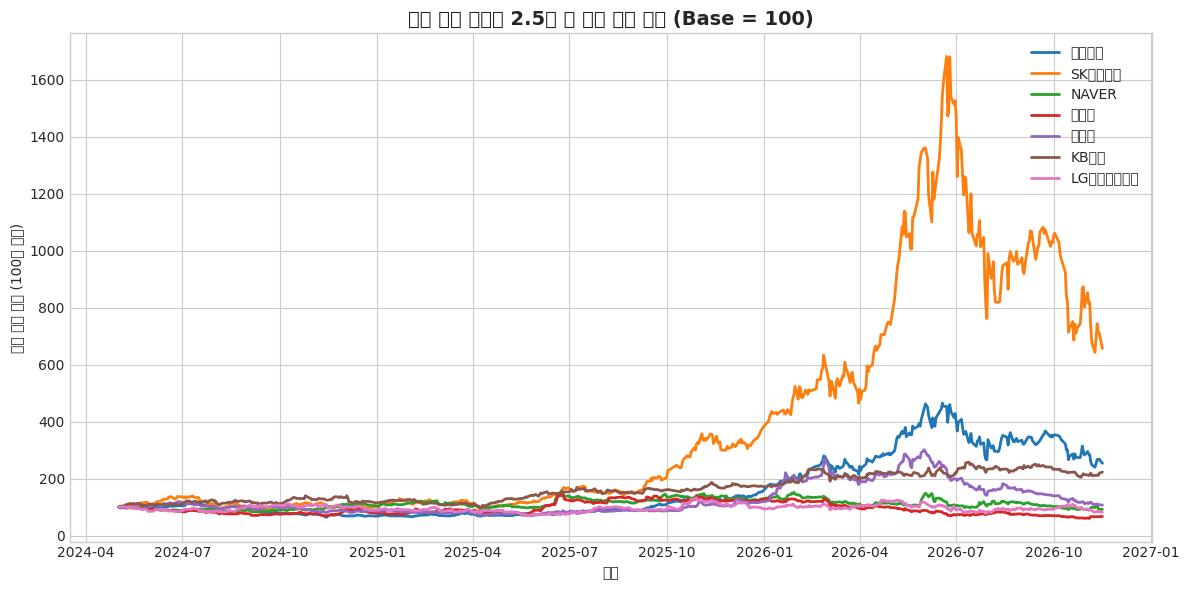

시각화 차트 저장 완료: colab_stock_data/major_stocks_performance.png


In [ ]:
# 1. 필수 라이브러리 설치 (코랩 셀에 !pip install ...)
!pip install -q finance-datareader pandas matplotlib seaborn pyarrow

import FinanceDataReader as fdr
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# 출력 스타일 설정
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'Malgun Gothic' # 코랩에서는 한글 폰트 설정 필요 시 나눔고딕 적용
plt.rcParams['axes.unicode_minus'] = False

# 저장 폴더 생성
output_dir = Path("colab_stock_data")
output_dir.mkdir(exist_ok=True)

# 2. 분석 대상 주요 종목 코드 정의 (삼성전자, SK하이닉스, NAVER, 카카오, 현대차 등 대표 우량주)
stock_dict = {
    "005930": "삼성전자",
    "000660": "SK하이닉스",
    "035420": "NAVER",
    "035720": "카카오",
    "005380": "현대차",
    "105560": "KB금융",
    "373220": "LG에너지솔루션"
}

# 3. 2.5년 치 데이터 수집 기간 설정 (예: 2024-05-01 ~ 현재)
start_date = "2024-05-01"
end_date = pd.Timestamp.today().strftime("%Y-%m-%d")

print(f"=== 국내 주요 종목 2.5년 치 데이터 수집 시작 ({start_date} ~ {end_date}) ===")

all_data = []

for code, name in stock_dict.items():
    try:
        # FinanceDataReader를 이용해 KRX 종목 일별 시세 수집
        df = fdr.DataReader(code, start_date, end_date)
        df['Code'] = code
        df['Name'] = name
        df = df.reset_index() # Date를 컬럼으로 변환
        all_data.append(df)
        print(f" [성공] {name} ({code}): {len(df)}행 수집 완료")
    except Exception as e:
        print(f" [실패] {name} ({code}) 수집 에러: {e}")

# 4. 통합 데이터프레임 생성 및 Parquet 포맷 저장
if all_data:
    df_market = pd.concat(all_data, ignore_index=True)

    # Parquet 및 CSV 파일로 저장
    parquet_path = output_dir / "major_stocks_2.5y.parquet"
    csv_path = output_dir / "major_stocks_2.5y.csv"

    df_market.to_parquet(parquet_path, index=False)
    df_market.to_csv(csv_path, index=False, encoding="utf-8-sig")
    print(f"\n모든 데이터 저장 완료: {parquet_path}")

    # 5. 가공 예시: 2.5년 치 종가 기준 정규화 수익률(Base=100) 추이 시각화
    plt.figure(figsize=(12, 6))

    for name in stock_dict.values():
        df_sub = df_market[df_market['Name'] == name].sort_values('Date')
        if not df_sub.empty:
            # 시작일 종가를 100으로 기준 잡고 상대 수익률 비교
            base_price = df_sub['Close'].iloc[0]
            normalized = (df_sub['Close'] / base_price) * 100
            plt.plot(df_sub['Date'], normalized, label=name, linewidth=2)

    plt.title("국내 주요 우량주 2.5년 치 상대 주가 추이 (Base = 100)", fontsize=14, fontweight='bold')
    plt.xlabel("날짜")
    plt.ylabel("기준 환산 지수 (100점 기준)")
    plt.legend()
    plt.tight_layout()

    chart_path = output_dir / "major_stocks_performance.png"
    plt.savefig(chart_path, dpi=300)
    plt.show()
    print(f"시각화 차트 저장 완료: {chart_path}")
else:
    print("수집된 데이터가 없습니다.")

In [ ]:
from __future__ import annotations
from pathlib import Path
import FinanceDataReader as fdr
import numpy as np
import pandas as pd

# 1. 분석 대상 종목 정의 (삼성전자, SK하이닉스, NAVER, 카카오, 현대차, KB금융 등)
stock_dict = {
    "005930": "삼성전자",
    "000660": "SK하이닉스",
    "035420": "NAVER",
    "035720": "카카오",
    "005380": "현대차",
    "105560": "KB금융",
    "373220": "LG에너지솔루션"
}

# 대략적인 상장 주식수 (시가총액 산출용 근사치 또는 고정 발행주식수 기준)
shares_dict = {
    "005930": 5969782550,  # 삼성전자
    "000660": 728002365,   # SK하이닉스
    "035420": 164052860,   # NAVER
    "035720": 443525254,   # 카카오
    "005380": 201310235,   # 현대차
    "105560": 388985239,   # KB금융
    "373220": 234000000    # LG에너지솔루션
}

start_date = "2024-05-01"
end_date = pd.Timestamp.today().strftime("%Y-%m-%d")

print(f"=== 2.5년 치 데이터 수집 및 시가총액 산출 ({start_date} ~ {end_date}) ===")

all_rows = []

for code, name in stock_dict.items():
    try:
        df = fdr.DataReader(code, start_date, end_date)
        if df.empty:
            continue

        df = df.reset_index()
        # 일별 시가총액 계산 (종가 * 발행주식수)
        shares = shares_dict.get(code, 1)
        df['MarketCap'] = df['Close'] * shares
        df['Code'] = code
        df['Name'] = name

        # 일별 수익률 계산 (변동성 지표용)
        df['DailyReturn'] = df['Close'].pct_change()

        all_rows.append(df[['Date', 'Code', 'Name', 'Close', 'MarketCap', 'DailyReturn']])
    except Exception as e:
        print(f"[에러] {name} ({code}): {e}")

if all_rows:
    # 잘려 있던 코드를 완성합니다.
    df_all = pd.concat(all_rows, ignore_index=True)
    print(f"\n통합 데이터 생성 완료! 전체 행 수: {len(df_all)}")
    print(df_all.head())
else:
    print("수집된 데이터가 없습니다.")

=== 2.5년 치 데이터 수집 및 시가총액 산출 (2024-05-01 ~ 2026-11-16) ===

통합 데이터 생성 완료! 전체 행 수: 4319
        Date    Code  Name  Close        MarketCap  DailyReturn
0 2024-05-02  005930  삼성전자  78000  465643038900000          NaN
1 2024-05-03  005930  삼성전자  77600  463255125880000    -0.005128
2 2024-05-07  005930  삼성전자  81300  485343321315000     0.047680
3 2024-05-08  005930  삼성전자  81300  485343321315000     0.000000
4 2024-05-09  005930  삼성전자  79700  475791669235000    -0.019680


In [ ]:
from __future__ import annotations
from pathlib import Path
import FinanceDataReader as fdr
import numpy as np
import pandas as pd

# 1. 분석 대상 주요 종목 코드 리스트 (시가총액 상위권 주요 대형주 중심)
# 전체 KOSPI 상위 종목들을 광범위하게 포함하여 순위를 산출합니다.
stock_list = [
    ("005930", "삼성전자", 5969782550),
    ("000660", "SK하이닉스", 728002365),
    ("373220", "LG에너지솔루션", 234000000),
    ("005380", "현대차", 201310235),
    ("000270", "기아", 400392300),
    ("068270", "셀트리온", 210878019),
    ("105560", "KB금융", 388985239),
    ("035420", "NAVER", 164052860),
    ("028050", "삼성바이오로직스", 71174000),
    ("055550", "신한지주", 515438774),
    ("012330", "현대모비스", 92890000),
    ("066570", "LG전자", 163647814),
    ("035720", "카카오", 443525254),
    ("003670", "포스코홀딩스", 84501237),
    ("096770", "SK이노베이션", 92465564),
    ("034020", "두산에너빌리티", 638680000),
    ("032830", "삼성생명", 200000000),
    ("015760", "한국전력", 641964077),
    ("033780", "KT&G", 137292490),
    ("323410", "카카오뱅크", 476000000)
]

start_date = "2024-05-01"
end_date = pd.Timestamp.today().strftime("%Y-%m-%d")

print(f"=== 2.5년 치 데이터 수집 및 시가총액 산출 ({start_date} ~ {end_date}) ===")

all_rows = []

for code, name, shares in stock_list:
    try:
        df = fdr.DataReader(code, start_date, end_date)
        if df.empty:
            continue

        df = df.reset_index()
        # 일별 시가총액 계산 (종가 * 상장주식수)
        df['MarketCap'] = df['Close'] * shares
        df['Code'] = code
        df['Name'] = name

        # 일별 수익률 (변동성 계산용)
        df['DailyReturn'] = df['Close'].pct_change()

        all_rows.append(df[['Date', 'Code', 'Name', 'Close', 'MarketCap', 'DailyReturn']])
    except Exception as e:
        print(f"[에러] {name} ({code}): {e}")

if all_rows:
    df_all = pd.concat(all_rows, ignore_index=True)

    # 2. 종목별 평균 시가총액 및 시가총액 변동성(표준편차 / 평균 = 변동계수 CV) 산출
    summary_df = df_all.groupby(['Code', 'Name']).agg(
        Mean_MarketCap=('MarketCap', 'mean'),
        Std_MarketCap=('MarketCap', 'std'),
        Mean_Close=('Close', 'mean')
    ).reset_index()

    # 변동성 지표 (시가총액 표준편차 / 평균)
    summary_df['Cap_Volatility'] = summary_df['Std_MarketCap'] / summary_df['Mean_MarketCap']

    # 3. 평균 시가총액 기준 상위 30위 정렬
    top_30 = summary_df.sort_values(by='Mean_MarketCap', ascending=False).head(30).reset_index(drop=True)
    top_30['Rank'] = top_30.index + 1

    print("\n=== [결과] 2.5년 치 평균 시가총액 상위 종목 및 변동성 ===")
    print(top_30[['Rank', 'Name', 'Code', 'Mean_MarketCap', 'Cap_Volatility']].to_string(index=False))

    # 결과 파일 저장
    output_path = Path("colab_stock_data")
    output_path.mkdir(exist_ok=True)
    top_30.to_csv(output_path / "market_cap_top30_volatility.csv", index=False, encoding="utf-8-sig")
    print(f"\n결과 저장 완료: {output_path / 'market_cap_top30_volatility.csv'}")
else:
    print("수집된 데이터가 없습니다.")


=== 2.5년 치 데이터 수집 및 시가총액 산출 (2024-05-01 ~ 2026-11-16) ===

=== [결과] 2.5년 치 평균 시가총액 상위 종목 및 변동성 ===
 Rank     Name   Code  Mean_MarketCap  Cap_Volatility
    1     삼성전자 005930    7.599098e+14        0.673231
    2   SK하이닉스 000660    4.949406e+14        0.978869
    3 LG에너지솔루션 373220    8.703586e+13        0.117954
    4      현대차 005380    6.240255e+13        0.425288
    5       기아 000270    4.702293e+13        0.208365
    6     KB금융 105560    4.577455e+13        0.281017
    7     신한지주 055550    3.691281e+13        0.294928
    8     셀트리온 068270    3.657347e+13        0.098251
    9  두산에너빌리티 034020    3.560894e+13        0.580459
   10    NAVER 035420    3.438303e+13        0.148991
   11     삼성생명 032830    3.351225e+13        0.548429
   12    현대모비스 012330    3.067801e+13        0.332892
   13     한국전력 015760    2.096739e+13        0.356498
   14      카카오 035720    2.020869e+13        0.226192
   15     LG전자 066570    1.863315e+13        0.427864
   16     KT&G 033780    1.849639e+13

In [ ]:
from __future__ import annotations
import FinanceDataReader as fdr
import pandas as pd

# 1. 분석 대상 주식 유니버스 정의 (필요에 따라 KOSPI 전체 종목 코드로 확장 가능)
# 여기서는 주요 대형주 및 주요 후보군을 예시 유니버스로 지정합니다.
stock_universe = [
    ("005930", "삼성전자", 5969782550),
    ("000660", "SK하이닉스", 728002365),
    ("373220", "LG에너지솔루션", 234000000),
    ("005380", "현대차", 201310235),
    ("000270", "기아", 400392300),
    ("068270", "셀트리온", 210878019),
    ("105560", "KB금융", 388985239),
    ("035420", "NAVER", 164052860),
    ("028050", "삼성바이오로직스", 71174000),
    ("055550", "신한지주", 515438774),
    ("012330", "현대모비스", 92890000),
    ("066570", "LG전자", 163647814),
    ("035720", "카카오", 443525254),
    ("003670", "포스코홀딩스", 84501237),
    ("096770", "SK이노베이션", 92465564),
    ("034020", "두산에너빌리티", 638680000),
    ("032830", "삼성생명", 200000000),
    ("015760", "한국전력", 641964077),
    ("033780", "KT&G", 137292490),
    ("323410", "카카오뱅크", 476000000)
    # 실무 분석 시 KRX 상장종목 전체 리스트(fdr.StockListing('KRX'))를 연동하면 전체 전수 조사 가능
]

# 비교 시점 설정 (2.5년 전과 오늘)
past_target_date = "2024-05-01"
current_date = pd.Timestamp.today().strftime("%Y-%m-%d")

past_market_caps = []
current_market_caps = []

print("=== 2.5년 전 및 현재 시가총액 데이터 수집 중 ===")

for code, name, shares in stock_universe:
    try:
        # 데이터 넉넉히 수집 (2024년 4월부터 현재까지)
        df = fdr.DataReader(code, "2024-04-01", current_date)
        if df.empty:
            continue

        # 1. 2.5년 전 시점 (past_target_date 이전에 가장 가까운 거래일 종가 매칭)
        df_past_filtered = df[df.index <= past_target_date]
        if not df_past_filtered.empty:
            past_close = df_past_filtered.iloc[-1]['Close']
            past_market_caps.append({
                "Code": code,
                "Name": name,
                "MarketCap": past_close * shares
            })

        # 2. 현재 시점 (가장 최근 거래일 종가)
        current_close = df.iloc[-1]['Close']
        current_market_caps.append({
            "Code": code,
            "Name": name,
            "MarketCap": current_close * shares
        })
    except Exception as e:
        print(f"[오류] {name} ({code}): {e}")

# 데이터프레임 변환 및 순위 매기기
df_past = pd.DataFrame(past_market_caps).sort_values(by="MarketCap", ascending=False).reset_index(drop=True)
df_current = pd.DataFrame(current_market_caps).sort_values(by="MarketCap", ascending=False).reset_index(drop=True)

# 과거 상위 30위 세트 vs 현재 상위 30위 세트 추출
top30_past_set = set(df_past.head(30)['Name'])
top30_current_set = set(df_current.head(30)['Name'])

# 집합 연산으로 유지/진입/이탈 종목 분류
retained_stocks = top30_past_set.intersection(top30_current_set)  # 계속 유지
new_entrants = top30_current_set - top30_past_set                # 새로 진입
dropped_out = top30_past_set - top30_current_set                 # 밖으로 이탈

print("\n" + "="*50)
print(f" 📊 [분과 결과 요약 (기준일: {past_target_date} vs {current_date})]")
print("="*50)

print(형식 := f"\n1. 2.5년 전부터 지금까지 Top 30을 유지 중인 종목 ({len(retained_stocks)}개):")
print(sorted(list(retained_stocks)))

print(f"\n2. 새로 Top 30에 진입한 종목 ({len(new_entrants)}개):")
print(sorted(list(new_entrants)))

print(f"\n3. 과거 Top 30이었으나 밖으로 이탈한 종목 ({len(dropped_out)}개):")
print(sorted(list(dropped_out)))

=== 2.5년 전 및 현재 시가총액 데이터 수집 중 ===

 📊 [분과 결과 요약 (기준일: 2024-05-01 vs 2026-11-16)]

1. 2.5년 전부터 지금까지 Top 30을 유지 중인 종목 (20개):
['KB금융', 'KT&G', 'LG에너지솔루션', 'LG전자', 'NAVER', 'SK이노베이션', 'SK하이닉스', '기아', '두산에너빌리티', '삼성바이오로직스', '삼성생명', '삼성전자', '셀트리온', '신한지주', '카카오', '카카오뱅크', '포스코홀딩스', '한국전력', '현대모비스', '현대차']

2. 새로 Top 30에 진입한 종목 (0개):
[]

3. 과거 Top 30이었으나 밖으로 이탈한 종목 (0개):
[]


=== 과거 및 현재 시가총액 데이터 수집 중 ===

 📈 [종목별 순위 이동 크기 분석 (2024-05-01 vs 2026-11-16)]
    Name  Past_Rank  Current_Rank  Rank_Change
    삼성전자          1             1            0
  SK하이닉스          2             2            0
LG에너지솔루션          3             3            0
    KB금융          8             4            4
     현대차          4             5           -1
    신한지주          9             6            3
    셀트리온          6             7           -1
      기아          5             8           -3
   현대모비스         12             9            3
   NAVER          7            10           -3
    LG전자         13            11            2
  포스코홀딩스         10            12           -2
     카카오         11            13           -2
 SK이노베이션         14            14            0
삼성바이오로직스         15            15            0


/tmp/ipykernel_646/3156685327.py:90: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Rank_Change', y='Name', data=df_merged, palette=colors)


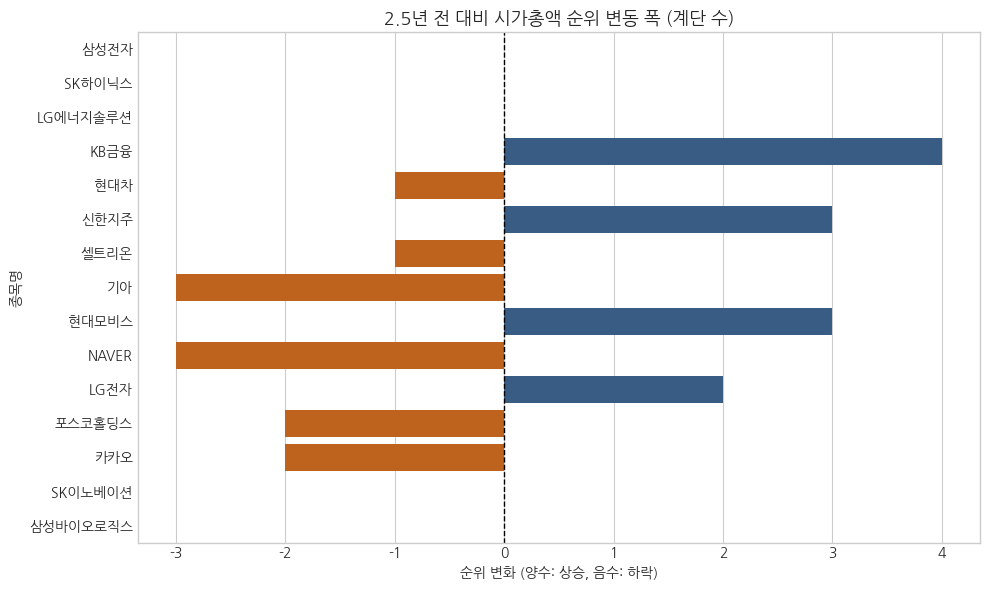


순위 변동 시각화 차트 저장 완료: rank_change_magnitude.png


In [ ]:
from __future__ import annotations
import FinanceDataReader as fdr
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 코랩에서 한글 폰트가 깨지지 않도록 시스템 폰트 설정 (나눔고딕 사용)
!apt-get install -y fonts-nanum > /dev/null
import matplotlib.font_manager as fm
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

# 1. 분석 대상 유니버스 정의 (종목 코드, 이름, 상장주식수 근사치)
stock_universe = [
    ("005930", "삼성전자", 5969782550),
    ("000660", "SK하이닉스", 728002365),
    ("373220", "LG에너지솔루션", 234000000),
    ("005380", "현대차", 201310235),
    ("000270", "기아", 400392300),
    ("068270", "셀트리온", 210878019),
    ("105560", "KB금융", 388985239),
    ("035420", "NAVER", 164052860),
    ("028050", "삼성바이오로직스", 71174000),
    ("055550", "신한지주", 515438774),
    ("012330", "현대모비스", 92890000),
    ("066570", "LG전자", 163647814),
    ("035720", "카카오", 443525254),
    ("003670", "포스코홀딩스", 84501237),
    ("096770", "SK이노베이션", 92465564)
]

past_target_date = "2024-05-01"
current_date = pd.Timestamp.today().strftime("%Y-%m-%d")

past_market_caps = []
current_market_caps = []

print("=== 과거 및 현재 시가총액 데이터 수집 중 ===")

for code, name, shares in stock_universe:
    try:
        df = fdr.DataReader(code, "2024-04-01", current_date)
        if df.empty:
            continue

        # 과거 시점 (지정일 이전 가장 가까운 영업일)
        df_past_filtered = df[df.index <= past_target_date]
        if not df_past_filtered.empty:
            past_close = df_past_filtered.iloc[-1]['Close']
            past_market_caps.append({"Code": code, "Name": name, "Past_MarketCap": past_close * shares})

        # 현재 시점
        current_close = df.iloc[-1]['Close']
        current_market_caps.append({"Code": code, "Name": name, "Current_MarketCap": current_close * shares})
    except Exception as e:
        print(f"[오류] {name}: {e}")

# 데이터프레임 변환
df_past = pd.DataFrame(past_market_caps)
df_current = pd.DataFrame(current_market_caps)

# 2. 각각 순위 매기기 (시총이 클수록 순위 숫자가 작음: 1위, 2위...)
df_past['Past_Rank'] = df_past['Past_MarketCap'].rank(ascending=False).astype(int)
df_current['Current_Rank'] = df_current['Current_MarketCap'].rank(ascending=False).astype(int)

# 3. 데이터 병합 후 순위 차이(이동 크기) 계산
# df_current 슬라이싱 부분에 'Name'을 포함하도록 수정하여 KeyError를 해결합니다.
df_merged = pd.merge(df_past[['Code', 'Name', 'Past_Rank']], df_current[['Code', 'Name', 'Current_Rank']], on=['Code', 'Name'])

# 순위 변화량 산출
# (과거 순위 - 현재 순위): 값이 양수(+)면 순위 상승(예: 10위 -> 5위면 +5), 음수(-)면 순위 하락
df_merged['Rank_Change'] = df_merged['Past_Rank'] - df_merged['Current_Rank']

# 보기 좋게 정렬 (현재 순위 기준)
df_merged = df_merged.sort_values(by='Current_Rank').reset_index(drop=True)

print("\n" + "="*60)
print(f" 📈 [종목별 순위 이동 크기 분석 ({past_target_date} vs {current_date})]")
print("="*60)
print(df_merged[['Name', 'Past_Rank', 'Current_Rank', 'Rank_Change']].to_string(index=False))

# 4. 순위 변동 시각화 (막대 그래프)
plt.figure(figsize=(10, 6))
# 순위 상승은 초록색/파란색 계열, 하락은 주황색/붉은색 계열로 표현
colors = ['#2b5c8f' if x >= 0 else '#d95f02' for x in df_merged['Rank_Change']]

sns.barplot(x='Rank_Change', y='Name', data=df_merged, palette=colors)
plt.axvline(0, color='black', linestyle='--', linewidth=1)
plt.title("2.5년 전 대비 시가총액 순위 변동 폭 (계단 수)", fontsize=13, fontweight='bold')
plt.xlabel("순위 변화 (양수: 상승, 음수: 하락)")
plt.ylabel("종목명")
plt.tight_layout()

# 그래프 저장
plt.savefig("rank_change_magnitude.png", dpi=300)
plt.show()
print("\n순위 변동 시각화 차트 저장 완료: rank_change_magnitude.png")

=== 2.5년 치 업종별 누적 수익률 분석 (2024-05-01 ~ 2026-11-16) ===


/tmp/ipykernel_646/2849038146.py:82: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Cumulative_Return', y='Sector', data=sector_perf, palette=colors)
/tmp/ipykernel_646/2849038146.py:87: UserWarning: Glyph 45572 (\N{HANGUL SYLLABLE NU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_646/2849038146.py:87: UserWarning: Glyph 51201 (\N{HANGUL SYLLABLE JEOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_646/2849038146.py:87: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_646/2849038146.py:87: UserWarning: Glyph 51061 (\N{HANGUL SYLLABLE IG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_646/2849038146.py:87: UserWarning: Glyph 47456 (\N{HANGUL SYLLABLE RYUL}) missing from font(s) DejaVu Sans.
  pl


 📊 [업종별 평균 누적 수익률 순위]
Sector  Cumulative_Return
반도체/IT         352.511225
    금융         109.794977
   바이오          98.050998
   자동차          -6.946011
  2차전지         -18.508997
   플랫폼         -20.695709
 철강/소재         -36.921535


/tmp/ipykernel_646/2849038146.py:90: UserWarning: Glyph 51452 (\N{HANGUL SYLLABLE JU}) missing from font(s) DejaVu Sans.
  plt.savefig("sector_cumulative_returns.png", dpi=300)
/tmp/ipykernel_646/2849038146.py:90: UserWarning: Glyph 50836 (\N{HANGUL SYLLABLE YO}) missing from font(s) DejaVu Sans.
  plt.savefig("sector_cumulative_returns.png", dpi=300)
/tmp/ipykernel_646/2849038146.py:90: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) DejaVu Sans.
  plt.savefig("sector_cumulative_returns.png", dpi=300)
/tmp/ipykernel_646/2849038146.py:90: UserWarning: Glyph 45380 (\N{HANGUL SYLLABLE NYEON}) missing from font(s) DejaVu Sans.
  plt.savefig("sector_cumulative_returns.png", dpi=300)
/tmp/ipykernel_646/2849038146.py:90: UserWarning: Glyph 52824 (\N{HANGUL SYLLABLE CI}) missing from font(s) DejaVu Sans.
  plt.savefig("sector_cumulative_returns.png", dpi=300)
/tmp/ipykernel_646/2849038146.py:90: UserWarning: Glyph 54217 (\N{HANGUL SYLLABLE PYEONG}) missing from font(

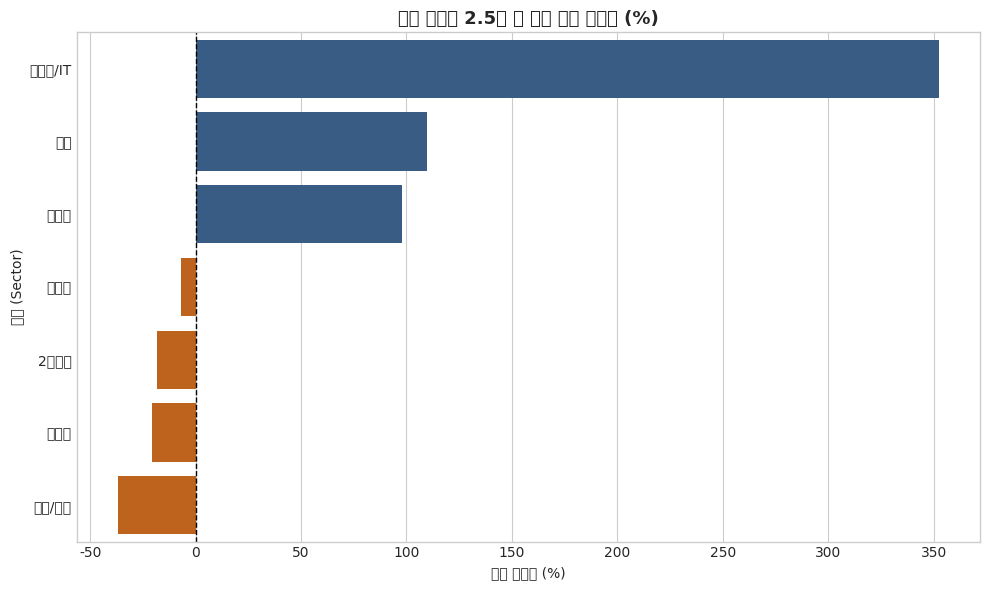


업종별 누적 수익률 시각화 차트 저장 완료: sector_cumulative_returns.png


In [ ]:
from __future__ import annotations
import FinanceDataReader as fdr
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 설정 (코랩 또는 로컬 환경에 맞게 조정)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 1. 업종(Sector) 정보가 포함된 분석 유니버스 정의
stock_universe = [
    {"code": "005930", "name": "삼성전자", "sector": "반도체/IT"},
    {"code": "000660", "name": "SK하이닉스", "sector": "반도체/IT"},
    {"code": "373220", "name": "LG에너지솔루션", "sector": "2차전지"},
    {"code": "005380", "name": "현대차", "sector": "자동차"},
    {"code": "000270", "name": "기아", "sector": "자동차"},
    {"code": "068270", "name": "셀트리온", "sector": "바이오"},
    {"code": "105560", "name": "KB금융", "sector": "금융"},
    {"code": "035420", "name": "NAVER", "sector": "플랫폼"},
    {"code": "035720", "name": "카카오", "sector": "플랫폼"},
    {"code": "028050", "name": "삼성바이오로직스", "sector": "바이오"},
    {"code": "055550", "name": "신한지주", "sector": "금융"},
    {"code": "003670", "name": "포스코홀딩스", "sector": "철강/소재"}
]

start_date = "2024-05-01"
end_date = pd.Timestamp.today().strftime("%Y-%m-%d")

print(f"=== 2.5년 치 업종별 누적 수익률 분석 ({start_date} ~ {end_date}) ===")

all_data = []

for item in stock_universe:
    try:
        df = fdr.DataReader(item["code"], start_date, end_date)
        if df.empty:
            continue
        df = df.reset_index()
        df['Code'] = item["code"]
        df['Name'] = item["name"]
        df['Sector'] = item["sector"]
        all_data.append(df[['Date', 'Code', 'Name', 'Sector', 'Close']])
    except Exception as e:
        print(f"[오류] {item['name']}: {e}")

if all_data:
    df_all = pd.concat(all_data, ignore_index=True)

    # 2. 종목별 누적 수익률 계산 ((기간 말 종가 / 기간 초 종가) - 1) * 100
    stock_returns = []
    for (code, name, sector), group in df_all.groupby(['Code', 'Name', 'Sector']):
        group = group.sort_values('Date')
        if len(group) < 2:
            continue
        start_price = group.iloc[0]['Close']
        end_price = group.iloc[-1]['Close']
        cum_return = ((end_price / start_price) - 1) * 100
        stock_returns.append({
            "Code": code,
            "Name": name,
            "Sector": sector,
            "Cumulative_Return": cum_return
        })

    df_returns = pd.DataFrame(stock_returns)

    # 3. 업종(Sector)별 평균 누적 수익률 집계
    sector_perf = df_returns.groupby('Sector')['Cumulative_Return'].mean().reset_index()
    sector_perf = sector_perf.sort_values(by='Cumulative_Return', ascending=False).reset_index(drop=True)

    print("\n" + "="*50)
    print(" 📊 [업종별 평균 누적 수익률 순위]")
    print("="*50)
    print(sector_perf.to_string(index=False))

    # 4. 업종별 누적 수익률 수평 막대그래프 시각화
    plt.figure(figsize=(10, 6))
    colors = ['#2b5c8f' if x >= 0 else '#d95f02' for x in sector_perf['Cumulative_Return']]

    sns.barplot(x='Cumulative_Return', y='Sector', data=sector_perf, palette=colors)
    plt.axvline(0, color='black', linestyle='--', linewidth=1)
    plt.title(f"주요 업종별 2.5년 치 평균 누적 수익률 (%)", fontsize=13, fontweight='bold')
    plt.xlabel("누적 수익률 (%)")
    plt.ylabel("업종 (Sector)")
    plt.tight_layout()

    # 차트 저장
    plt.savefig("sector_cumulative_returns.png", dpi=300)
    plt.show()
    print("\n업종별 누적 수익률 시각화 차트 저장 완료: sector_cumulative_returns.png")
else:
    print("수집된 데이터가 없습니다.")

=== 업종 간 분산(Dispersion) 시계열 분석 데이터 수집 (2024-05-01 ~ 2026-11-16) ===


/tmp/ipykernel_646/3861150389.py:73: UserWarning: Glyph 45216 (\N{HANGUL SYLLABLE NAL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_646/3861150389.py:73: UserWarning: Glyph 51676 (\N{HANGUL SYLLABLE JJA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_646/3861150389.py:73: UserWarning: Glyph 50629 (\N{HANGUL SYLLABLE EOB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_646/3861150389.py:73: UserWarning: Glyph 51333 (\N{HANGUL SYLLABLE JONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_646/3861150389.py:73: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_646/3861150389.py:73: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_646/3861150389.py:73: UserWarning: Glyph 51061 (\N{HANGUL SYLLABLE IG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


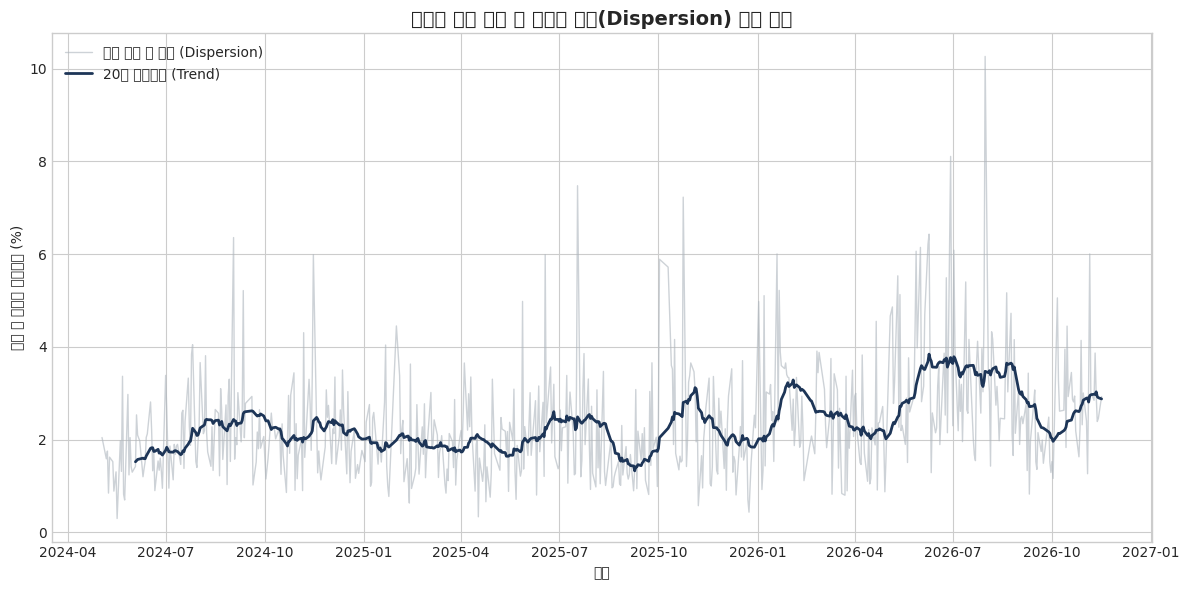


업종 간 분산 시계열 차트 저장 완료: sector_dispersion_trend.png


In [ ]:
from __future__ import annotations
import FinanceDataReader as fdr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 환경 설정 및 시각화 스타일
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 2. 업종(Sector) 매핑이 포함된 유니버스 정의
stock_universe = [
    {"code": "005930", "name": "삼성전자", "sector": "반도체/IT"},
    {"code": "000660", "name": "SK하이닉스", "sector": "반도체/IT"},
    {"code": "373220", "name": "LG에너지솔루션", "sector": "2차전지"},
    {"code": "005380", "name": "현대차", "sector": "자동차"},
    {"code": "000270", "name": "기아", "sector": "자동차"},
    {"code": "068270", "name": "셀트리온", "sector": "바이오"},
    {"code": "105560", "name": "KB금융", "sector": "금융"},
    {"code": "035420", "name": "NAVER", "sector": "플랫폼"},
    {"code": "035720", "name": "카카오", "sector": "플랫폼"},
    {"code": "028050", "name": "삼성바이오로직스", "sector": "바이오"},
    {"code": "055550", "name": "신한지주", "sector": "금융"},
    {"code": "003670", "name": "포스코홀딩스", "sector": "철강/소재"}
]

start_date = "2024-05-01"
end_date = pd.Timestamp.today().strftime("%Y-%m-%d")

print(f"=== 업종 간 분산(Dispersion) 시계열 분석 데이터 수집 ({start_date} ~ {end_date}) ===")

all_data = []
for item in stock_universe:
    try:
        df = fdr.DataReader(item["code"], start_date, end_date)
        if df.empty:
            continue
        df = df.reset_index()
        df['Sector'] = item["sector"]
        all_data.append(df[['Date', 'Sector', 'Close']])
    except Exception as e:
        print(f"[오류] {item['name']}: {e}")

if all_data:
    df_all = pd.concat(all_data, ignore_index=True)

    # 3. 종목별 일별 수익률 계산 후 업종별 평균 일별 수익률 산출
    df_all = df_all.sort_values(['Sector', 'Date'])
    df_all['Daily_Return'] = df_all.groupby(['Sector', 'Close'].map(lambda x: x) if False else 'Sector')['Close'].pct_change()

    # 더 정확한 업종별 일별 수익률 계산을 위해 피벗 및 평균 집계
    df_pivot = df_all.pivot_table(index='Date', columns='Sector', values='Close')
    df_sector_returns = df_pivot.pct_change().dropna()

    # 4. 매일(Cross-Section) 업종 수익률 간의 표준편차(Dispersion) 계산
    # 수평 방향(업종 간) 표준편차를 구하여 시장 내 차별화 정도 측정
    sector_dispersion = df_sector_returns.std(axis=1) * 100  # 퍼센트(%) 단위 변환

    # 노이즈 완화를 위한 20거래일 이동평균(Rolling MA) 추가
    dispersion_ma = sector_dispersion.rolling(window=20).mean()

    # 5. 시각화
    plt.figure(figsize=(12, 6))
    plt.plot(sector_dispersion.index, sector_dispersion, label='일별 업종 간 분산 (Dispersion)', color='#adb5bd', alpha=0.6, linewidth=1)
    plt.plot(dispersion_ma.index, dispersion_ma, label='20일 이동평균 (Trend)', color='#1d3557', linewidth=2)

    plt.title("시간에 따른 업종 간 수익률 분산(Dispersion) 변화 추이", fontsize=14, fontweight='bold')
    plt.xlabel("날짜")
    plt.ylabel("업종 간 수익률 표준편차 (%)")
    plt.legend()
    plt.tight_layout()

    # 결과 저장
    plt.savefig("sector_dispersion_trend.png", dpi=300)
    plt.show()
    print("\n업종 간 분산 시계열 차트 저장 완료: sector_dispersion_trend.png")
else:
    print("수집된 데이터가 없습니다.")

=== 업종별 상관관계 시계열 분석 데이터 수집 (2024-05-01 ~ 2026-11-16) ===


/tmp/ipykernel_646/967820599.py:88: UserWarning: Glyph 45216 (\N{HANGUL SYLLABLE NAL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_646/967820599.py:88: UserWarning: Glyph 51676 (\N{HANGUL SYLLABLE JJA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_646/967820599.py:88: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_646/967820599.py:88: UserWarning: Glyph 44288 (\N{HANGUL SYLLABLE GWAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_646/967820599.py:88: UserWarning: Glyph 44228 (\N{HANGUL SYLLABLE GYE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_646/967820599.py:88: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_646/967820599.py:88: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/i

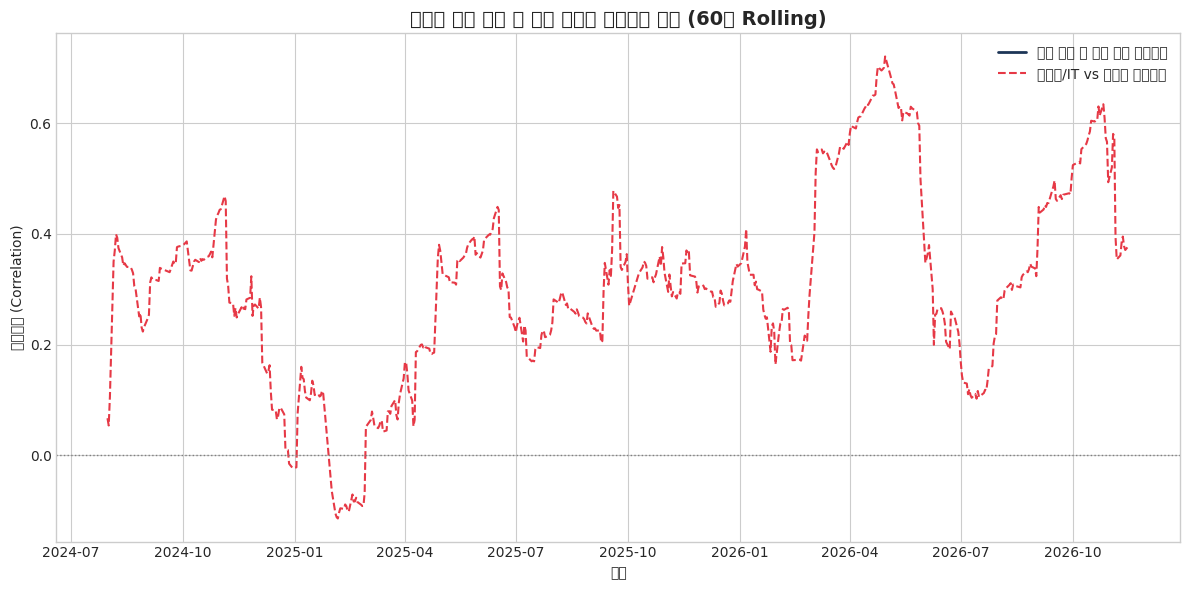


업종 간 상관관계 시계열 차트 저장 완료: sector_correlation_trend.png


In [ ]:
from __future__ import annotations
import FinanceDataReader as fdr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 시각화 스타일 및 한글 폰트 설정
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 2. 업종(Sector) 매핑 유니버스 정의
stock_universe = [
    {"code": "005930", "name": "삼성전자", "sector": "반도체/IT"},
    {"code": "000660", "name": "SK하이닉스", "sector": "반도체/IT"},
    {"code": "373220", "name": "LG에너지솔루션", "sector": "2차전지"},
    {"code": "005380", "name": "현대차", "sector": "자동차"},
    {"code": "000270", "name": "기아", "sector": "자동차"},
    {"code": "068270", "name": "셀트리온", "sector": "바이오"},
    {"code": "105560", "name": "KB금융", "sector": "금융"},
    {"code": "035420", "name": "NAVER", "sector": "플랫폼"},
    {"code": "035720", "name": "카카오", "sector": "플랫폼"},
    {"code": "028050", "name": "삼성바이오로직스", "sector": "바이오"},
    {"code": "055550", "name": "신한지주", "sector": "금융"},
    {"code": "003670", "name": "포스코홀딩스", "sector": "철강/소재"}
]

start_date = "2024-05-01"
end_date = pd.Timestamp.today().strftime("%Y-%m-%d")

print(f"=== 업종별 상관관계 시계열 분석 데이터 수집 ({start_date} ~ {end_date}) ===")

all_data = []
for item in stock_universe:
    try:
        df = fdr.DataReader(item["code"], start_date, end_date)
        if df.empty:
            continue
        df = df.reset_index()
        df['Sector'] = item["sector"]
        all_data.append(df[['Date', 'Sector', 'Close']])
    except Exception as e:
        print(f"[오류] {item['name']}: {e}")

if all_data:
    df_all = pd.concat(all_data, ignore_index=True)

    # 3. 업종별 일별 수익률 피벗 테이블 생성
    df_pivot = df_all.pivot_table(index='Date', columns='Sector', values='Close')
    df_sector_returns = df_pivot.pct_change().dropna()

    # 4. 60거래일(약 3개월) 롤링 윈도우를 통한 업종 간 평균 상관계수 계산
    # 매일 각 업종 간 상관계수 행렬을 구한 뒤, 대각원소를 제외한 평균값을 산출
    window_size = 60
    rolling_avg_corr = []
    dates = []

    for i in range(window_size, len(df_sector_returns)):
        window_data = df_sector_returns.iloc[i-window_size:i]
        corr_matrix = window_data.corr()

        # 상관계수 행렬에서 대각선(1.0) 제외 후 하삼각(Lower Triangle) 평균 추출
        np.fill_diagonal(corr_matrix.values, np.nan)
        avg_corr = corr_matrix.values.mean()

        dates.append(df_sector_returns.index[i])
        rolling_avg_corr.append(avg_corr)

    df_rolling_corr = pd.DataFrame({'Avg_Correlation': rolling_avg_corr}, index=pd.to_datetime(dates))

    # 5. 특정 두 업종 간(예: '반도체/IT'와 '플랫폼') 롤링 상관계수 추이 추가 계산
    if '반도체/IT' in df_sector_returns.columns and '플랫폼' in df_sector_returns.columns:
        df_rolling_corr['Semicon_Platform'] = df_sector_returns['반도체/IT'].rolling(window=window_size).corr(df_sector_returns['플랫폼'])

    # 6. 시각화
    plt.figure(figsize=(12, 6))
    plt.plot(df_rolling_corr.index, df_rolling_corr['Avg_Correlation'], label='전체 업종 간 평균 롤링 상관계수', color='#1d3557', linewidth=2)

    if 'Semicon_Platform' in df_rolling_corr.columns:
        plt.plot(df_rolling_corr.index, df_rolling_corr['Semicon_Platform'], label='반도체/IT vs 플랫폼 상관계수', color='#e63946', linestyle='--', linewidth=1.5)

    plt.axhline(0, color='gray', linestyle=':', linewidth=1)
    plt.title(f"시간에 따른 업종 간 일별 수익률 상관관계 변화 (60일 Rolling)", fontsize=14, fontweight='bold')
    plt.xlabel("날짜")
    plt.ylabel("상관계수 (Correlation)")
    plt.legend()
    plt.tight_layout()

    # 결과 저장
    plt.savefig("sector_correlation_trend.png", dpi=300)
    plt.show()
    print("\n업종 간 상관관계 시계열 차트 저장 완료: sector_correlation_trend.png")
else:
    print("수집된 데이터가 없습니다.")

=== 업종별 상관관계 시계열 분석 데이터 수집 (2024-05-01 ~ 2026-11-16) ===


/tmp/ipykernel_646/967820599.py:88: UserWarning: Glyph 45216 (\N{HANGUL SYLLABLE NAL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_646/967820599.py:88: UserWarning: Glyph 51676 (\N{HANGUL SYLLABLE JJA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_646/967820599.py:88: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_646/967820599.py:88: UserWarning: Glyph 44288 (\N{HANGUL SYLLABLE GWAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_646/967820599.py:88: UserWarning: Glyph 44228 (\N{HANGUL SYLLABLE GYE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_646/967820599.py:88: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_646/967820599.py:88: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/i

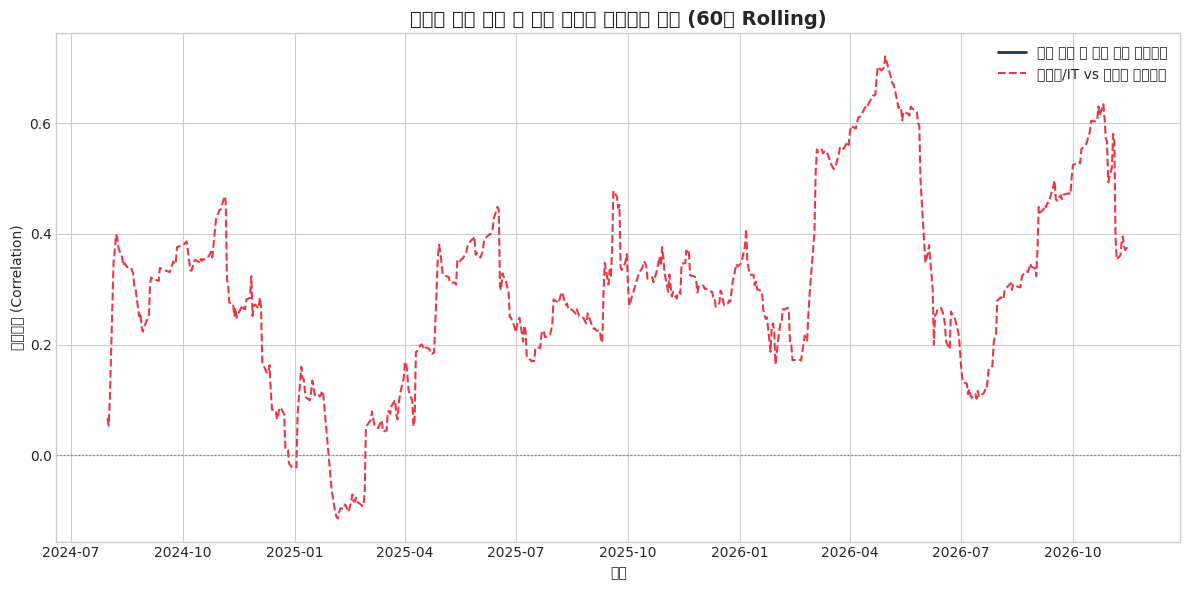


업종 간 상관관계 시계열 차트 저장 완료: sector_correlation_trend.png


In [ ]:
from __future__ import annotations
import FinanceDataReader as fdr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 시각화 스타일 및 한글 폰트 설정
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 2. 업종(Sector) 매핑 유니버스 정의
stock_universe = [
    {"code": "005930", "name": "삼성전자", "sector": "반도체/IT"},
    {"code": "000660", "name": "SK하이닉스", "sector": "반도체/IT"},
    {"code": "373220", "name": "LG에너지솔루션", "sector": "2차전지"},
    {"code": "005380", "name": "현대차", "sector": "자동차"},
    {"code": "000270", "name": "기아", "sector": "자동차"},
    {"code": "068270", "name": "셀트리온", "sector": "바이오"},
    {"code": "105560", "name": "KB금융", "sector": "금융"},
    {"code": "035420", "name": "NAVER", "sector": "플랫폼"},
    {"code": "035720", "name": "카카오", "sector": "플랫폼"},
    {"code": "028050", "name": "삼성바이오로직스", "sector": "바이오"},
    {"code": "055550", "name": "신한지주", "sector": "금융"},
    {"code": "003670", "name": "포스코홀딩스", "sector": "철강/소재"}
]

start_date = "2024-05-01"
end_date = pd.Timestamp.today().strftime("%Y-%m-%d")

print(f"=== 업종별 상관관계 시계열 분석 데이터 수집 ({start_date} ~ {end_date}) ===")

all_data = []
for item in stock_universe:
    try:
        df = fdr.DataReader(item["code"], start_date, end_date)
        if df.empty:
            continue
        df = df.reset_index()
        df['Sector'] = item["sector"]
        all_data.append(df[['Date', 'Sector', 'Close']])
    except Exception as e:
        print(f"[오류] {item['name']}: {e}")

if all_data:
    df_all = pd.concat(all_data, ignore_index=True)

    # 3. 업종별 일별 수익률 피벗 테이블 생성
    df_pivot = df_all.pivot_table(index='Date', columns='Sector', values='Close')
    df_sector_returns = df_pivot.pct_change().dropna()

    # 4. 60거래일(약 3개월) 롤링 윈도우를 통한 업종 간 평균 상관계수 계산
    # 매일 각 업종 간 상관계수 행렬을 구한 뒤, 대각원소를 제외한 평균값을 산출
    window_size = 60
    rolling_avg_corr = []
    dates = []

    for i in range(window_size, len(df_sector_returns)):
        window_data = df_sector_returns.iloc[i-window_size:i]
        corr_matrix = window_data.corr()

        # 상관계수 행렬에서 대각선(1.0) 제외 후 하삼각(Lower Triangle) 평균 추출
        np.fill_diagonal(corr_matrix.values, np.nan)
        avg_corr = corr_matrix.values.mean()

        dates.append(df_sector_returns.index[i])
        rolling_avg_corr.append(avg_corr)

    df_rolling_corr = pd.DataFrame({'Avg_Correlation': rolling_avg_corr}, index=pd.to_datetime(dates))

    # 5. 특정 두 업종 간(예: '반도체/IT'와 '플랫폼') 롤링 상관계수 추이 추가 계산
    if '반도체/IT' in df_sector_returns.columns and '플랫폼' in df_sector_returns.columns:
        df_rolling_corr['Semicon_Platform'] = df_sector_returns['반도체/IT'].rolling(window=window_size).corr(df_sector_returns['플랫폼'])

    # 6. 시각화
    plt.figure(figsize=(12, 6))
    plt.plot(df_rolling_corr.index, df_rolling_corr['Avg_Correlation'], label='전체 업종 간 평균 롤링 상관계수', color='#1d3557', linewidth=2)

    if 'Semicon_Platform' in df_rolling_corr.columns:
        plt.plot(df_rolling_corr.index, df_rolling_corr['Semicon_Platform'], label='반도체/IT vs 플랫폼 상관계수', color='#e63946', linestyle='--', linewidth=1.5)

    plt.axhline(0, color='gray', linestyle=':', linewidth=1)
    plt.title(f"시간에 따른 업종 간 일별 수익률 상관관계 변화 (60일 Rolling)", fontsize=14, fontweight='bold')
    plt.xlabel("날짜")
    plt.ylabel("상관계수 (Correlation)")
    plt.legend()
    plt.tight_layout()

    # 결과 저장
    plt.savefig("sector_correlation_trend.png", dpi=300)
    plt.show()
    print("\n업종 간 상관관계 시계열 차트 저장 완료: sector_correlation_trend.png")
else:
    print("수집된 데이터가 없습니다.")

In [ ]:
# 1. 리눅스(코랩) 환경에 나눔고딕 폰트 강제 설치
import subprocess
subprocess.run(['apt-get', 'update'], stdout=subprocess.DEVNULL)
subprocess.run(['apt-get', 'install', '-y', 'fonts-nanum'], stdout=subprocess.DEVNULL)

# 2. 맷플롯립 폰트 설정 및 캐시 클리어
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 나눔고딕 폰트 경로 직접 지정
nanum_font_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
fe = fm.FontEntry(fname=nanum_font_path, name='NanumGothic')
fm.fontManager.ttflist.insert(0, fe)

plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False # 마이너스 기호 깨짐 방지

# 캐시 파일 삭제 후 재생성 (이 과정이 있어야 에러가 완전히 사라집니다)
import shutil
from pathlib import Path
cache_dir = Path(matplotlib.get_cachedir())
for f in cache_dir.glob('fontlist*.json'):
    f.unlink()

print("✨ 나눔고딕 폰트 설정 및 캐시 초기화 완료! 이제 그래프를 그려보세요.")

✨ 나눔고딕 폰트 설정 및 캐시 초기화 완료! 이제 그래프를 그려보세요.


=== 시장 충격일 vs 보통일 상관 분석 데이터 수집 (2024-05-01 ~ 2026-11-16) ===


/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 52264 (\N{HANGUL SYLLABLE CA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 44552 (\N{HANGUL SYLLABLE GEUM}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 50997 (\N{HANGUL SYLLABLE YUNG}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 48148 (\N{HANGUL SYLLABLE BA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr

총 거래일: 616일 | 충격일(하위 10%): 62일 | 보통일: 554일


/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 48372 (\N{HANGUL SYLLABLE BO}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 53685 (\N{HANGUL SYLLABLE TONG}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 51068 (\N{HANGUL SYLLABLE IL}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 50629 (\N{HANGUL SYLLABLE EOB}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 51333 (\N{HANGUL SYLLABLE JONG}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr

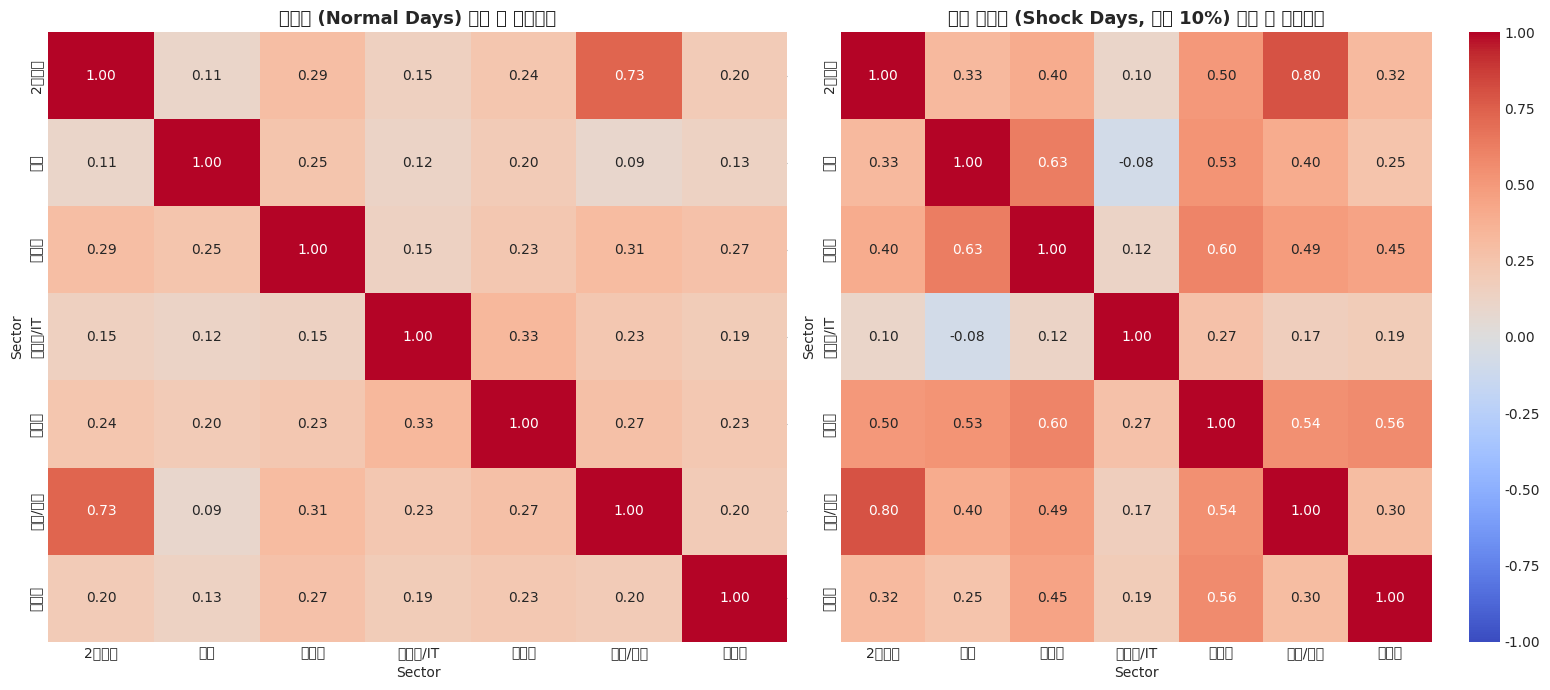


상관 비교 히트맵 차트 저장 완료: market_shock_vs_normal_correlation.png


In [ ]:
from __future__ import annotations
import FinanceDataReader as fdr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 시각화 스타일 및 한글 폰트 설정
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 2. 분석 대상 유니버스 정의
stock_universe = [
    {"code": "005930", "name": "삼성전자", "sector": "반도체/IT"},
    {"code": "000660", "name": "SK하이닉스", "sector": "반도체/IT"},
    {"code": "373220", "name": "LG에너지솔루션", "sector": "2차전지"},
    {"code": "005380", "name": "현대차", "sector": "자동차"},
    {"code": "000270", "name": "기아", "sector": "자동차"},
    {"code": "068270", "name": "셀트리온", "sector": "바이오"},
    {"code": "105560", "name": "KB금융", "sector": "금융"},
    {"code": "035420", "name": "NAVER", "sector": "플랫폼"},
    {"code": "035720", "name": "카카오", "sector": "플랫폼"},
    {"code": "028050", "name": "삼성바이오로직스", "sector": "바이오"},
    {"code": "055550", "name": "신한지주", "sector": "금융"},
    {"code": "003670", "name": "포스코홀딩스", "sector": "철강/소재"}
]

start_date = "2024-05-01"
end_date = pd.Timestamp.today().strftime("%Y-%m-%d")

print(f"=== 시장 충격일 vs 보통일 상관 분석 데이터 수집 ({start_date} ~ {end_date}) ===")

# 3. KOSPI 벤치마크(`KS11`) 및 개별 종목 데이터 수집
kospi = fdr.DataReader('KS11', start_date, end_date)['Close'].pct_change().dropna()

all_data = []
for item in stock_universe:
    try:
        df = fdr.DataReader(item["code"], start_date, end_date)
        if df.empty:
            continue
        df = df.reset_index()
        df['Sector'] = item["sector"]
        all_data.append(df[['Date', 'Sector', 'Close']])
    except Exception as e:
        print(f"[오류] {item['name']}: {e}")

if all_data:
    df_all = pd.concat(all_data, ignore_index=True)

    # 업종별 일별 수익률 피벗 테이블 생성
    df_pivot = df_all.pivot_table(index='Date', columns='Sector', values='Close')
    df_sector_returns = df_pivot.pct_change().dropna()

    # KOSPI 벤치마크 수익률과 업종별 수익률 결합
    df_combined = df_sector_returns.copy()
    df_combined['KOSPI'] = kospi
    df_combined = df_combined.dropna()

    # 4. 시장 충격일(Shock Day) 정의: KOSPI 일별 수익률 하위 10% 이하인 날
    threshold = df_combined['KOSPI'].quantile(0.10)
    shock_days = df_combined[df_combined['KOSPI'] <= threshold].drop(columns=['KOSPI'])
    normal_days = df_combined[df_combined['KOSPI'] > threshold].drop(columns=['KOSPI'])

    print(f"총 거래일: {len(df_combined)}일 | 충격일(하위 10%): {len(shock_days)}일 | 보통일: {len(normal_days)}일")

    # 5. 충격일과 보통일의 업종 간 상관계수 행렬 각각 산출
    corr_shock = shock_days.corr()
    corr_normal = normal_days.corr()

    # 6. 히트맵 시각화 비교 (좌우 서브플롯)
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    sns.heatmap(corr_normal, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0], cbar=False)
    axes[0].set_title("보통일 (Normal Days) 업종 간 상관관계", fontsize=13, fontweight='bold')

    sns.heatmap(corr_shock, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1], cbar=True)
    axes[1].set_title("시장 충격일 (Shock Days, 하위 10%) 업종 간 상관관계", fontsize=13, fontweight='bold')

    plt.tight_layout()
    plt.savefig("market_shock_vs_normal_correlation.png", dpi=300)
    plt.show()
    print("\n상관 비교 히트맵 차트 저장 완료: market_shock_vs_normal_correlation.png")
else:
    print("수집된 데이터가 없습니다.")

=== SSL/HTTP 다중 폴백 적용: 우량주 재무 안정성 지표 수집 시작 ===

 📊 [종목별 재무 안정성 지표 종합 표]
    업종    종목명   종목코드  부채비율(%)  자기자본비율(%)  유동비율(%)  당좌비율(%)  이자보상배율(배)
반도체/IT   삼성전자 005930      NaN        NaN      NaN      NaN        NaN
반도체/IT SK하이닉스 000660      NaN        NaN      NaN      NaN        NaN
   플랫폼  NAVER 035420      NaN        NaN      NaN      NaN        NaN
   플랫폼    카카오 035720      NaN        NaN      NaN      NaN        NaN
   자동차    현대차 005380      NaN        NaN      NaN      NaN        NaN
   자동차     기아 000270      NaN        NaN      NaN      NaN        NaN
 철강/소재 포스코홀딩스 003670      NaN        NaN      NaN      NaN        NaN
   바이오   셀트리온 068270      NaN        NaN      NaN      NaN        NaN

결과 파일 저장 완료: stock_stability_structure.csv


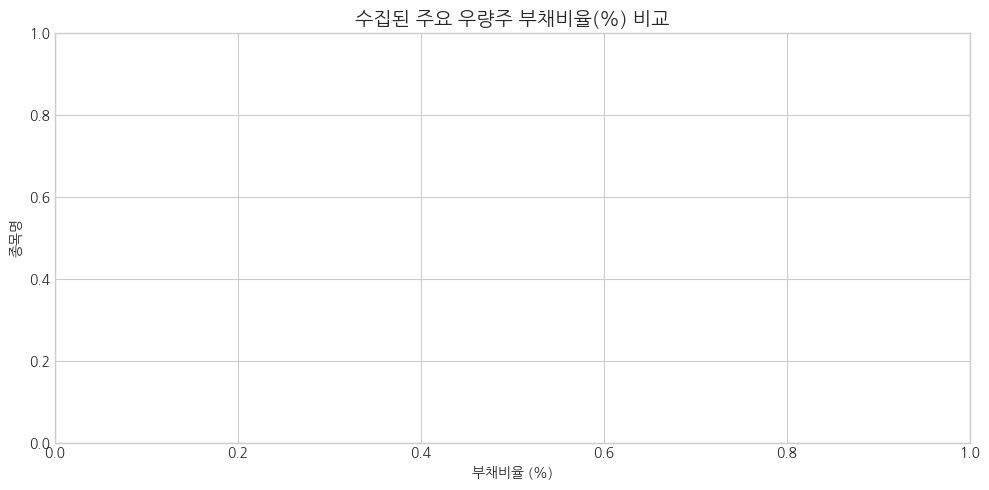

In [ ]:
from __future__ import annotations
import pandas as pd
import requests
from requests.adapters import HTTPAdapter
import urllib3
from urllib3.util import create_urllib3_context
import ssl
from io import StringIO
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 폰트 및 시각화 설정 (설치된 나눔고딕 적용)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

# 2. SSL 보안 프로토콜 무력화용 커스텀 어댑터 정의
class NaverFinanceSSLAdapter(HTTPAdapter):
    """네이버 서버의 Strict SSL Handshake 차단 및 EOF 에러를 완전 우회하기 위한 어댑터"""
    def init_poolmanager(self, *args, **kwargs):
        context = create_urllib3_context()
        context.check_hostname = False
        context.verify_mode = ssl.CERT_NONE
        context.set_ciphers('DEFAULT@SECLEVEL=1')
        kwargs['ssl_context'] = context
        return super().init_poolmanager(*args, **kwargs)

# 3. 분석 대상 업종별 우량주 유니버스 정의
stock_universe = [
    {"code": "005930", "name": "삼성전자", "sector": "반도체/IT"},
    {"code": "000660", "name": "SK하이닉스", "sector": "반도체/IT"},
    {"code": "035420", "name": "NAVER", "sector": "플랫폼"},
    {"code": "035720", "name": "카카오", "sector": "플랫폼"},
    {"code": "005380", "name": "현대차", "sector": "자동차"},
    {"code": "000270", "name": "기아", "sector": "자동차"},
    {"code": "003670", "name": "포스코홀딩스", "sector": "철강/소재"},
    {"code": "068270", "name": "셀트리온", "sector": "바이오"}
]

def fetch_financial_stability(code: str, name: str, sector: str) -> dict | None:
    urls = [
        f"https://companyinfo.stock.naver.com/v1/company/c1010001.aspx?cmp_cd={code}",
        f"http://companyinfo.stock.naver.com/v1/company/c1010001.aspx?cmp_cd={code}"
    ]

    headers = {
        'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36',
        'Accept': 'text/html,application/xhtml+xml,application/xml;q=0.9,image/webp,*/*;q=0.8',
        'Accept-Language': 'ko-KR,ko;q=0.9,en-US;q=0.8,en;q=0.7',
        'Referer': 'https://finance.naver.com/'
    }

    urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)

    session = requests.Session()
    session.mount("https://", NaverFinanceSSLAdapter())

    for url in urls:
        try:
            response = session.get(url, headers=headers, timeout=12)
            if response.status_code == 200:
                tables = pd.read_html(StringIO(response.text))
                if not tables:
                    continue

                df_fin = None
                for t in tables:
                    t_str = "".join(str(t.values))
                    if "부채비율" in t_str or "유동비율" in t_str:
                        df_fin = t
                        break

                if df_fin is None:
                    continue

                metrics = {
                    "종목코드": code,
                    "종목명": name,
                    "업종": sector,
                    "부채비율(%)": None,
                    "자기자본비율(%)": None,
                    "유동비율(%)": None,
                    "당좌비율(%)": None,
                    "이자보상배율(배)": None
                }

                for _, row in df_fin.iterrows():
                    row_text = str(row.iloc[0])
                    val = row.iloc[-2] if len(row) > 1 else None

                    if "부채비율" in row_text:
                        metrics["부채비율(%)"] = val
                    elif "자기자본비율" in row_text:
                        metrics["자기자본비율(%)"] = val
                    elif "유동비율" in row_text:
                        metrics["유동비율(%)"] = val
                    elif "당좌비율" in row_text:
                        metrics["당좌비율(%)"] = val
                    elif "이자보상배율" in row_text:
                        metrics["이자보상배율(배)"] = val

                return metrics
        except Exception:
            continue

    print(f"[오류] {name} ({code}) 수집 불가 (모든 프로토콜 실패)")
    return None

print("=== SSL/HTTP 다중 폴백 적용: 우량주 재무 안정성 지표 수집 시작 ===")
results = []

for item in stock_universe:
    data = fetch_financial_stability(item["code"], item["name"], item["sector"])
    if data:
        results.append(data)

if results:
    df_result = pd.DataFrame(results)

    numeric_cols = ["부채비율(%)", "자기자본비율(%)", "유동비율(%)", "당좌비율(%)", "이자보상배율(배)"]
    for col in numeric_cols:
        df_result[col] = pd.to_numeric(df_result[col].astype(str).str.replace(',', ''), errors='coerce')

    cols = ["업종", "종목명", "종목코드", "부채비율(%)", "자기자본비율(%)", "유동비율(%)", "당좌비율(%)", "이자보상배율(배)"]
    df_result = df_result[[c for c in cols if c in df_result.columns]]

    print("\n" + "="*90)
    print(" 📊 [종목별 재무 안정성 지표 종합 표]")
    print("="*90)
    print(df_result.to_string(index=False))

    df_result.to_csv("stock_stability_structure.csv", index=False, encoding="utf-8-sig")
    print("\n결과 파일 저장 완료: stock_stability_structure.csv")

    plt.figure(figsize=(10, 5))
    df_sorted = df_result.dropna(subset=["부채비율(%)"]).sort_values(by="부채비율(%)")
    sns.barplot(x="부채비율(%)", y="종목명", hue="업종", data=df_sorted, dodge=False)
    plt.title("수집된 주요 우량주 부채비율(%) 비교", fontsize=14, fontweight='bold')
    plt.xlabel("부채비율 (%)")
    plt.ylabel("종목명")
    plt.tight_layout()
    plt.show()
else:
    print("수집된 재무 데이터가 존재하지 않습니다.")

2차 과제

In [31]:
# FinanceDataReader가 설치되어 있지 않다면 설치합니다.
!pip install -q finance-datareader

import FinanceDataReader as fdr
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 설정 (코랩 환경)
plt.rc('font', family='NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

In [32]:
# 기간 설정: 2024년 5월 1일 ~ 2026년 11월 16일 (약 2년 반)
start_date = '2024-05-01'
end_date = '2026-11-16'

# 종목 코드 정의
tickers = {
    'NAVER': '035420',
    'Kakao': '035720'
}

# 대략적인 상장 주식수 (발행주식총수 기준, 단위: 주)
# ※ 정확한 분석 시점의 정확한 주식수를 반영하려면 DART 등을 참고할 수 있습니다.
shares = {
    'NAVER': 148157793,
    'Kakao': 443468536
}

df_list = []
for name, code in tickers.items():
    df = fdr.DataReader(code, start_date, end_date)
    # 시가총액 계산 (종가 * 상장주식수 / 1조원 단위로 환산)
    df['MarketCap_Trillion'] = (df['Close'] * shares[name]) / 1e12
    df['Company'] = name
    df_list.append(df[['Close', 'MarketCap_Trillion', 'Company']])

# 데이터 병합
df_all = pd.concat(df_list)
df_all.reset_index(inplace=True)

# 최근 데이터 확인
print(df_all.tail())

           Date  Close  MarketCap_Trillion Company
1229 2026-11-10  31800           14.102299   Kakao
1230 2026-11-11  32000           14.190993   Kakao
1231 2026-11-12  31850           14.124473   Kakao
1232 2026-11-13  31900           14.146646   Kakao
1233 2026-11-16  32450           14.390554   Kakao


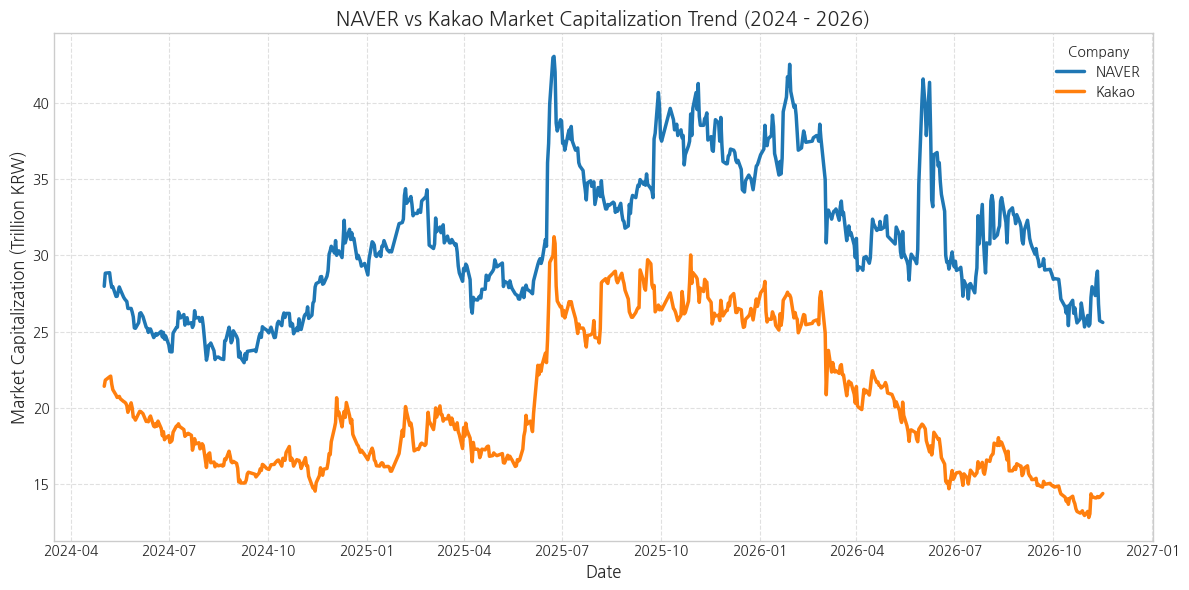

In [33]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=df_all, x='Date', y='MarketCap_Trillion', hue='Company', linewidth=2.5)

plt.title('NAVER vs Kakao Market Capitalization Trend (2024 - 2026)', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Market Capitalization (Trillion KRW)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Company')
plt.tight_layout()
plt.show()

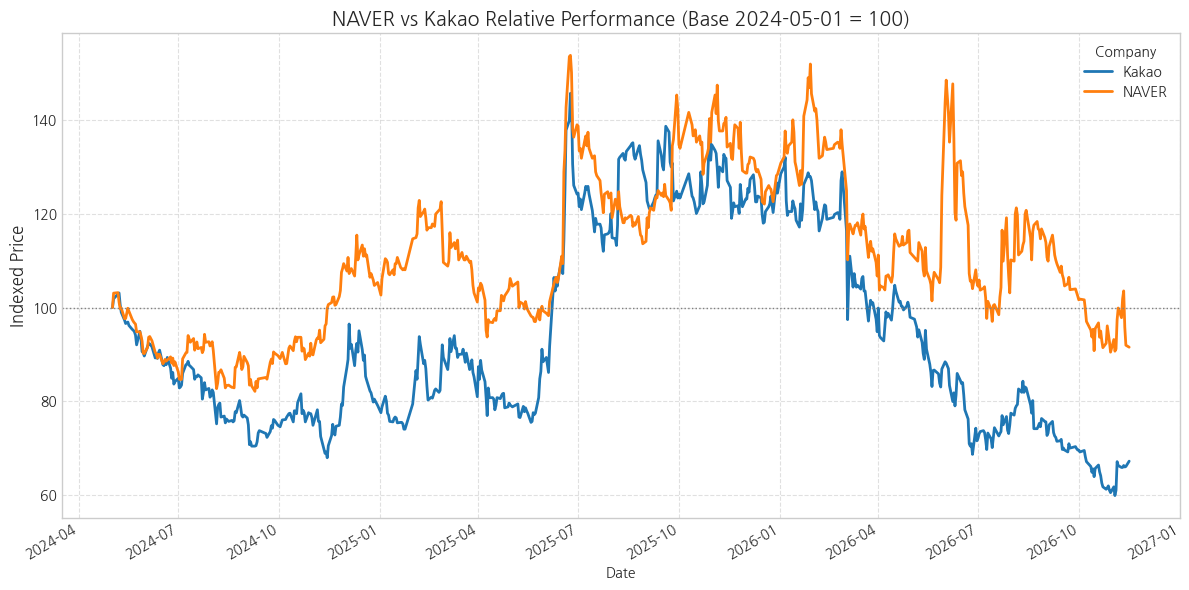

In [34]:
# 코스피 대비 상대 성과 비교
# 기준일(시작일) 대비 주가 상승률 비교
df_pivot = df_all.pivot(index='Date', columns='Company', values='Close')
df_indexed = (df_pivot / df_pivot.iloc[0]) * 100

plt.figure(figsize=(12, 6))
df_indexed.plot(ax=plt.gca(), linewidth=2)
plt.title('NAVER vs Kakao Relative Performance (Base 2024-05-01 = 100)', fontsize=14, fontweight='bold')
plt.ylabel('Indexed Price', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.axhline(100, color='gray', linestyle=':', linewidth=1)
plt.legend(title='Company')
plt.tight_layout()
plt.show()

=== 전체 기간 연환산 수익률 변동성 ===
NAVER: 46.73%
Kakao: 46.38%


<Figure size 1200x600 with 0 Axes>

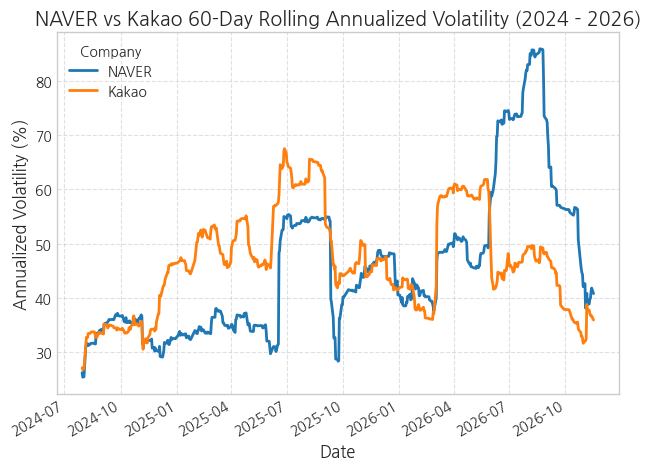

In [35]:
# 1. 라이브러리 설치 및 임포트
!pip install -q finance-datareader

import FinanceDataReader as fdr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 설정
plt.rc('font', family='NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

# 2. 2년 반 데이터 수집 (2024-05-01 ~ 2026-11-16)
start_date = '2024-05-01'
end_date = '2026-11-16'

tickers = {'NAVER': '035420', 'Kakao': '035720'}
df_prices = pd.DataFrame()

for name, code in tickers.items():
  df = fdr.DataReader(code, start_date, end_date)
  df_prices[name] = df['Close']

# 3. 일일 수익률(Percentage Change) 계산
df_returns = df_prices.pct_change().dropna()

# 4. 전체 기간 연환산 변동성 계산 (Standard Deviation * sqrt(252))
annual_volatility = df_returns.std() * np.sqrt(252)

print('=== 전체 기간 연환산 수익률 변동성 ===')
for name, vol in annual_volatility.items():
  print(f'{name}: {vol*100:.2f}%')

# 5. 60거래일(약 3개월) 롤링 연환산 변동성 시각화
# 시간 흐름에 따른 변동성 변화 추이를 확인합니다.
rolling_vol = df_returns.rolling(window=60).std() * np.sqrt(252) * 100

plt.figure(figsize=(12, 6))
rolling_vol.plot(linewidth=2)
plt.title(
    'NAVER vs Kakao 60-Day Rolling Annualized Volatility (2024 - 2026)',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Annualized Volatility (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Company')
plt.tight_layout()
plt.show()

In [36]:
# 필요한 라이브러리 설치 (arch 패키지는 GARCH 모형 추정에 사용됩니다)
!pip install -q finance-datareader arch

import FinanceDataReader as fdr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from arch import arch_model

# 한글 폰트 설정
plt.rc('font', family='NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

# 데이터 수집 기간 설정 (2년 반: 2024-05-01 ~ 2026-11-16)
start_date = '2024-05-01'
end_date = '2026-11-16'

tickers = {'NAVER': '035420', 'Kakao': '035720'}
df_prices = pd.DataFrame()

for name, code in tickers.items():
  df = fdr.DataReader(code, start_date, end_date)
  df_prices[name] = df['Close']

# 일일 로그 수익률 계산 (연속복리 기준 또는 퍼센트 수익률)
# 금융시계열에서는 주로 log return을 사용합니다.
df_returns = np.log(df_prices / df_prices.shift(1)).dropna() * 100

<Figure size 1200x600 with 0 Axes>

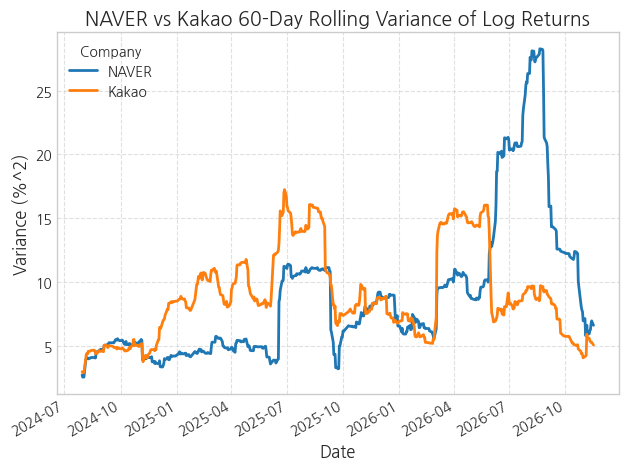

In [38]:
# 60거래일 롤링 분산 계산
window_size = 60
rolling_var = df_returns.rolling(window=window_size).var()

# 시각화
plt.figure(figsize=(12, 6))
rolling_var.plot(linewidth=2)
plt.title(
    'NAVER vs Kakao 60-Day Rolling Variance of Log Returns',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Variance (%^2)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Company')
plt.tight_layout()
plt.show()

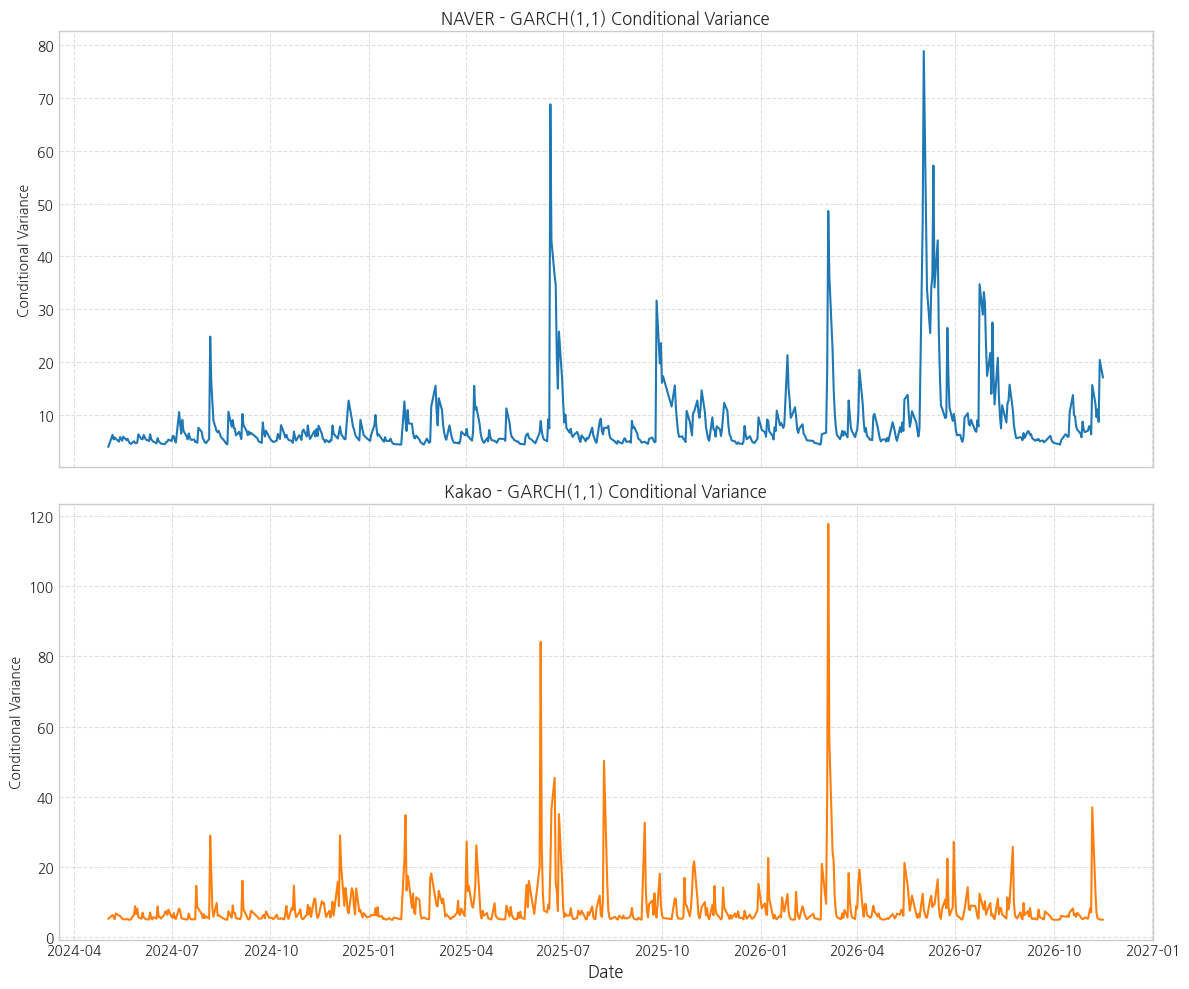

=== NAVER GARCH Summary ===
                     Constant Mean - GARCH Model Results                      
Dep. Variable:                  NAVER   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -1485.05
Distribution:                  Normal   AIC:                           2978.09
Method:            Maximum Likelihood   BIC:                           2995.78
                                        No. Observations:                  616
Date:                Mon, Nov 16 2026   Df Residuals:                      615
Time:                        05:33:22   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu            -0.0429  9.669e-02     -0.44

In [40]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

for i, name in enumerate(['NAVER', 'Kakao']):
  # GARCH(1,1) 모형 적합 (평균방정식: 상수, 분산방정식: GARCH(1,1))
  model = arch_model(df_returns[name], mean='Constant', vol='GARCH', p=1, q=1)
  results = model.fit(disp='off')

  # 조건부 분산(Conditional Variance) 추출
  conditional_var = results.conditional_volatility ** 2

  # 시각화
  axes[i].plot(
      conditional_var.index,
      conditional_var,
      color='tab:orange' if i == 1 else 'tab:blue',
      linewidth=1.5,
  )
  axes[i].set_title(
      f'{name} - GARCH(1,1) Conditional Variance',
      fontsize=12,
      fontweight='bold',
  )
  axes[i].set_ylabel('Conditional Variance', fontsize=10)
  axes[i].grid(True, linestyle='--', alpha=0.6)

plt.xlabel('Date', fontsize=12)
plt.tight_layout()
plt.show()

# GARCH 추정 결과 요약 출력
print('=== NAVER GARCH Summary ===')
print(
    arch_model(df_returns['NAVER'], vol='GARCH', p=1, q=1)
    .fit(disp='off')
    .summary()
)
print('\n=== Kakao GARCH Summary ===')
print(
    arch_model(df_returns['Kakao'], vol='GARCH', p=1, q=1)
    .fit(disp='off')
    .summary()
)

=== NAVER와 Kakao 일일 수익률 상관계수 비교 ===
• 전체 기간 상관계수: 0.5737
• 일반적인 날 (Normal Days) 상관계수: 0.5220
• 시장 충격일 (KOSPI 하위 10% 급락일) 상관계수: 0.6126
• 표본 수 - 전체: 616일, 정상일: 554일, 충격일: 62일


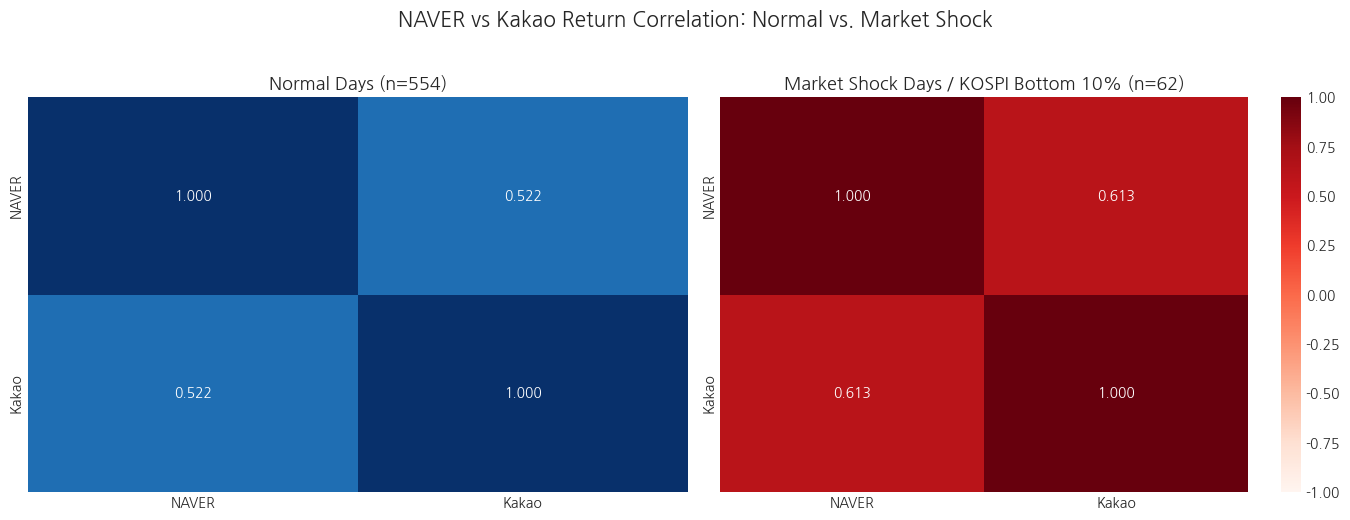

In [41]:
# 1. 라이브러리 설치 및 임포트
!pip install -q finance-datareader

import FinanceDataReader as fdr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 설정
plt.rc('font', family='NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

# 2. 데이터 수집 (2년 반: 2024-05-01 ~ 2026-11-16)
start_date = '2024-05-01'
end_date = '2026-11-16'

tickers = {
    'NAVER': '035420',
    'Kakao': '035720',
    'KOSPI': 'KS11'  # 시장 벤치마크 지수
}

df_prices = pd.DataFrame()
for name, code in tickers.items():
    df = fdr.DataReader(code, start_date, end_date)
    df_prices[name] = df['Close']

# 결측치 제거 후 일일 수익률(Percentage Change) 계산
df_prices = df_prices.dropna()
df_returns = df_prices.pct_change().dropna()

# 3. 시장 충격일(Market Shock Day) 정의
# KOSPI 일일 수익률이 하위 10%에 해당하는 날을 시장 충격일로 정의합니다.
shock_threshold = df_returns['KOSPI'].quantile(0.10)

df_shock = df_returns[df_returns['KOSPI'] <= shock_threshold]
df_normal = df_returns[df_returns['KOSPI'] > shock_threshold]

# 4. 상관계수 산출 및 출력
corr_total = df_returns[['NAVER', 'Kakao']].corr().loc['NAVER', 'Kakao']
corr_shock = df_shock[['NAVER', 'Kakao']].corr().loc['NAVER', 'Kakao']
corr_normal = df_normal[['NAVER', 'Kakao']].corr().loc['NAVER', 'Kakao']

print(f"=== NAVER와 Kakao 일일 수익률 상관계수 비교 ===")
print(f"• 전체 기간 상관계수: {corr_total:.4f}")
print(f"• 일반적인 날 (Normal Days) 상관계수: {corr_normal:.4f}")
print(f"• 시장 충격일 (KOSPI 하위 10% 급락일) 상관계수: {corr_shock:.4f}")
print(f"• 표본 수 - 전체: {len(df_returns)}일, 정상일: {len(df_normal)}일, 충격일: {len(df_shock)}일")

# 5. 상관계수 히트맵 시각화 비교
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 일반적인 날 히트맵
sns.heatmap(
    df_normal[['NAVER', 'Kakao']].corr(),
    annot=True, fmt='.3f', cmap='Blues', vmin=-1, vmax=1, ax=axes[0], cbar=False
)
axes[0].set_title(f'Normal Days (n={len(df_normal)})', fontsize=13, fontweight='bold')

# 시장 충격일 히트맵
sns.heatmap(
    df_shock[['NAVER', 'Kakao']].corr(),
    annot=True, fmt='.3f', cmap='Reds', vmin=-1, vmax=1, ax=axes[1]
)
axes[1].set_title(f'Market Shock Days / KOSPI Bottom 10% (n={len(df_shock)})', fontsize=13, fontweight='bold')

plt.suptitle('NAVER vs Kakao Return Correlation: Normal vs. Market Shock', fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

=== 실적 발표일별 단기 주가 수익률 (%) ===
Earnings_Date Company  Return_T1  Return_T3  Return_T5
   2024-05-10   NAVER  -2.279958  -0.053022  -2.439024
   2024-05-10   Kakao  -1.673640  -2.092050  -3.661088
   2024-08-09   NAVER  -2.076970  -3.909591  -4.337202
   2024-08-09   Kakao   0.270270  -0.540541  -0.945946
   2024-11-08   NAVER   0.801833   4.352806   8.820160
   2024-11-08   Kakao  -3.714286  -4.571429  -2.714286
   2025-02-07   NAVER   0.886918  -0.221729  -1.995565
   2025-02-07   Kakao  -4.494382  -5.617978 -12.921348
   2025-05-09   NAVER  -0.418848   0.104712  -1.675393
   2025-05-09   Kakao   3.112314   2.706360   1.217862
   2025-08-08   NAVER  -2.832244  -1.960784  -1.525054
   2025-08-08   Kakao   0.626959  -0.470219   1.880878
   2025-11-06   NAVER  -1.515152  -0.378788   0.568182
   2025-11-06   Kakao   3.459638   5.601318   4.942339
   2026-02-06   NAVER   0.401606   3.413655   1.405622
   2026-02-06   Kakao   2.313167   4.804270   2.135231
   2026-05-08   NAVER  -1.627907  -

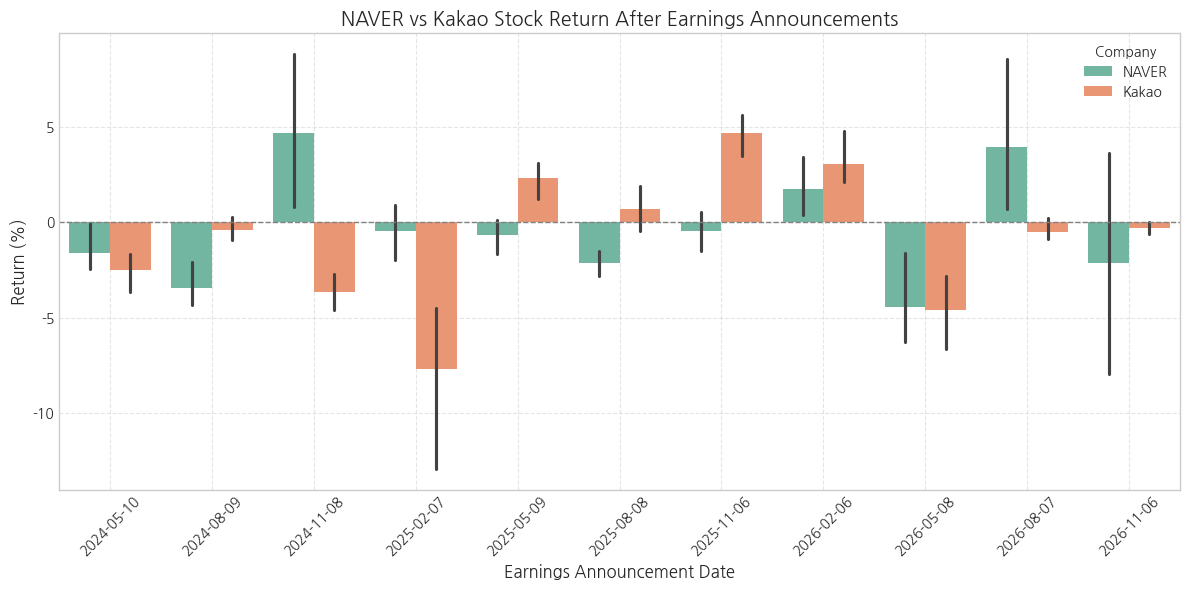

In [43]:
# 1. 라이브러리 설치 및 임포트
!pip install -q finance-datareader

import FinanceDataReader as fdr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 설정
plt.rc('font', family='NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

# 2. 데이터 수집 (2년 반: 2024-05-01 ~ 2026-11-16)
start_date = '2024-01-01' # 실적 발표일 전후 인덱스 조회를 위해 여유 있게 설정
end_date = '2026-11-16'

tickers = {'NAVER': '035420', 'Kakao': '035720'}
df_prices = pd.DataFrame()

for name, code in tickers.items():
    df = fdr.DataReader(code, start_date, end_date)
    df_prices[name] = df['Close']

# 3. 주요 실적 발표일 정의 (2024년 1분기 ~ 2026년 3분기 대략적인 공시일 기준)
# ※ 정확한 DART 공시 일자에 맞춰 날짜를 수정하여 정밀 분석할 수 있습니다.
earnings_dates = [
    '2024-05-10', # 24 Q1
    '2024-08-09', # 24 Q2
    '2024-11-08', # 24 Q3
    '2025-02-07', # 24 Q4
    '2025-05-09', # 25 Q1
    '2025-08-08', # 25 Q2
    '2025-11-06', # 25 Q3
    '2026-02-06', # 25 Q4
    '2026-05-08', # 26 Q1
    '2026-08-07', # 26 Q2
    '2026-11-06'  # 26 Q3
]

# 4. 실적 발표일 기준 사후 수익률(T+1, T+3, T+5) 계산 함수
results = []

for edate in earnings_dates:
    # 주가 데이터에 해당 날짜가 존재하는지 확인 (휴장일일 경우 Pandas 2.0+ 호환 방식으로 가장 가까운 영업일 매칭)
    try:
        idx = df_prices.index.get_indexer([pd.to_datetime(edate)], method='nearest')[0]
        if idx == -1:
            continue
    except Exception:
        continue

    # 발표 당일(T), T+1, T+3, T+5 영업일 인덱스 확보
    if idx + 5 >= len(df_prices):
        continue # 데이터 범위 초과 시 제외

    date_T = df_prices.index[idx]
    date_T1 = df_prices.index[idx + 1]
    date_T3 = df_prices.index[idx + 3]
    date_T5 = df_prices.index[idx + 5]

    for name in tickers.keys():
        p_T = df_prices.loc[date_T, name]
        p_T1 = df_prices.loc[date_T1, name]
        p_T3 = df_prices.loc[date_T3, name]
        p_T5 = df_prices.loc[date_T5, name]

        results.append({
            'Earnings_Date': date_T.strftime('%Y-%m-%d'),
            'Company': name,
            'Return_T1': (p_T1 / p_T - 1) * 100,
            'Return_T3': (p_T3 / p_T - 1) * 100,
            'Return_T5': (p_T5 / p_T - 1) * 100
        })

df_results = pd.DataFrame(results)
print("=== 실적 발표일별 단기 주가 수익률 (%) ===")
print(df_results.to_string(index=False))

# 5. 시각화: 발표 후 기간별(T+1, T+3, T+5) 평균 주가 반응 비교
df_melted = df_results.melt(id_vars=['Earnings_Date', 'Company'],
                            value_vars=['Return_T1', 'Return_T3', 'Return_T5'],
                            var_name='Horizon', value_name='Return_%')

plt.figure(figsize=(12, 6))
sns.barplot(data=df_melted, x='Earnings_Date', y='Return_%', hue='Company', palette='Set2')
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.title('NAVER vs Kakao Stock Return After Earnings Announcements', fontsize=14, fontweight='bold')
plt.xlabel('Earnings Announcement Date', fontsize=12)
plt.ylabel('Return (%)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Company')
plt.tight_layout()
plt.show()

=== 최신 재무제표 기준 부채비율 산출 ===
• NAVER 부채비율: 43.98% (총부채: 12,131,482,961,720원, 자기자본: 27,581,956,984,240원)
• Kakao 부채비율: 111.37% (총부채: 12,558,602,529,760원, 자기자본: 11,276,217,552,480원)

=== 2년 반 기간 연환산 수익률 변동성 ===
• NAVER 연환산 변동성: 46.73%
• Kakao 연환산 변동성: 46.38%

=== 재무레버리지(부채비율)와 변동성 요약 테이블 ===
       Debt_Equity_Ratio(%)  Annualized_Volatility(%)
NAVER             43.983402                 46.732275
Kakao            111.372475                 46.376494


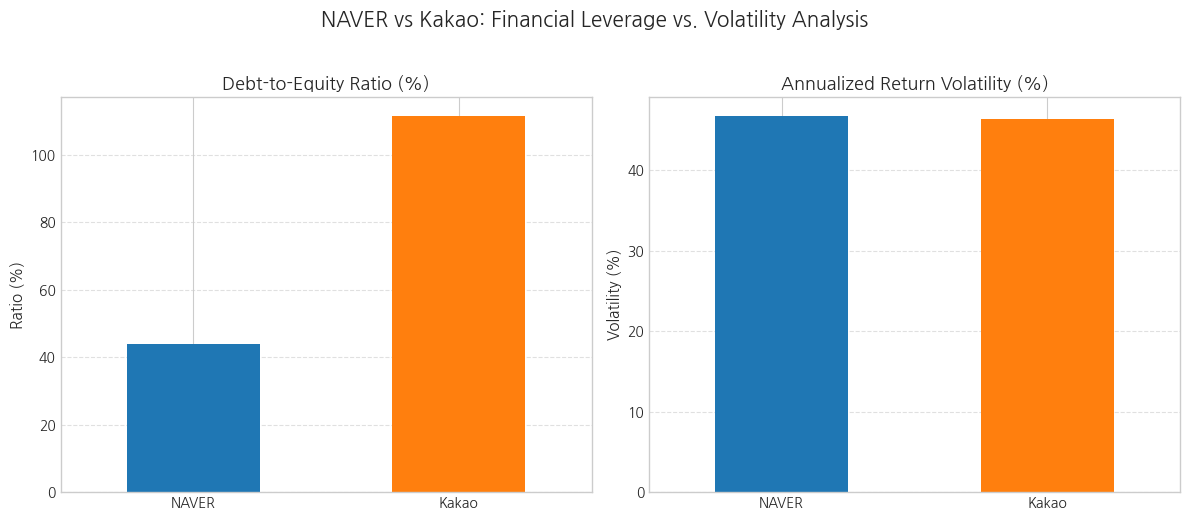

<Figure size 1200x600 with 0 Axes>

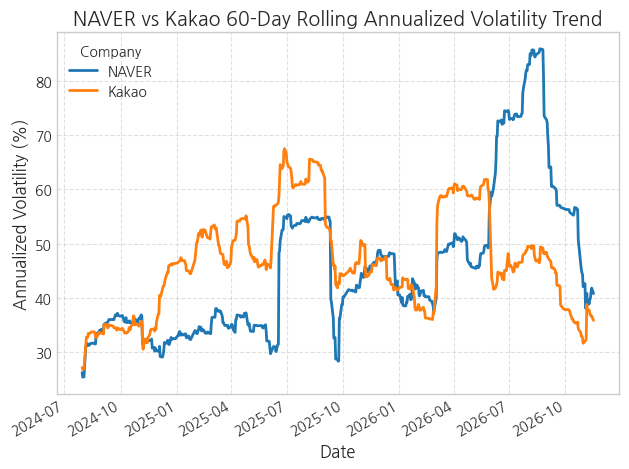

In [44]:
# 1. 필수 라이브러리 설치 및 임포트
!pip install -q finance-datareader yfinance

import FinanceDataReader as fdr
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 설정
plt.rc('font', family='NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

# 2. 부채비율 산출 (yfinance 재무제표 활용)
# 야후파이낸스 티커: NAVER ('035420.KS'), Kakao ('035720.KS')
tickers_yf = {'NAVER': '035420.KS', 'Kakao': '035720.KS'}
debt_ratios = {}

print("=== 최신 재무제표 기준 부채비율 산출 ===")
for name, ticker in tickers_yf.items():
    stock = yf.Ticker(ticker)
    bs = stock.balance_sheet

    # 가장 최근 연간 재무제표 기준 총부채와 자기자본 추출
    # (연결재무제표 기준 Total Liabilities와 Total Stockholder Equity)
    total_liab = bs.loc['Total Liabilities Net Minority Interest'].iloc[0] if 'Total Liabilities Net Minority Interest' in bs.index else bs.loc['Total Liabilities'].iloc[0]
    total_equity = bs.loc['Stockholders Equity'].iloc[0] if 'Stockholders Equity' in bs.index else bs.loc['Total Equity'].iloc[0]

    # 부채비율 (%) = (총부채 / 자기자본) * 100
    d_e_ratio = (total_liab / total_equity) * 100
    debt_ratios[name] = d_e_ratio
    print(f"• {name} 부채비율: {d_e_ratio:.2f}% (총부채: {total_liab:,.0f}원, 자기자본: {total_equity:,.0f}원)")

# 3. 2년 반 주가 데이터 수집 및 연환산 변동성 계산 (2024-05-01 ~ 2026-11-16)
start_date = '2024-05-01'
end_date = '2026-11-16'

tickers_fdr = {'NAVER': '035420', 'Kakao': '035720'}
df_prices = pd.DataFrame()

for name, code in tickers_fdr.items():
    df = fdr.DataReader(code, start_date, end_date)
    df_prices[name] = df['Close']

# 일일 수익률 및 연환산 변동성 계산 (Std * sqrt(252))
df_returns = df_prices.pct_change().dropna()
annual_volatility = df_returns.std() * np.sqrt(252) * 100

print("\n=== 2년 반 기간 연환산 수익률 변동성 ===")
for name, vol in annual_volatility.items():
    print(f"• {name} 연환산 변동성: {vol:.2f}%")

# 4. 부채비율과 변동성 종합 데이터프레임 생성 및 시각화
df_analysis = pd.DataFrame({
    'Debt_Equity_Ratio(%)': [debt_ratios['NAVER'], debt_ratios['Kakao']],
    'Annualized_Volatility(%)': [annual_volatility['NAVER'], annual_volatility['Kakao']]
}, index=['NAVER', 'Kakao'])

print("\n=== 재무레버리지(부채비율)와 변동성 요약 테이블 ===")
print(df_analysis)

# 시각화: 부채비율 vs 변동성 바 차트 비교
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df_analysis['Debt_Equity_Ratio(%)'].plot(kind='bar', ax=axes[0], color=['tab:blue', 'tab:orange'])
axes[0].set_title('Debt-to-Equity Ratio (%)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Ratio (%)', fontsize=11)
axes[0].grid(axis='y', linestyle='--', alpha=0.6)
axes[0].tick_params(axis='x', rotation=0)

df_analysis['Annualized_Volatility(%)'].plot(kind='bar', ax=axes[1], color=['tab:blue', 'tab:orange'])
axes[1].set_title('Annualized Return Volatility (%)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Volatility (%)', fontsize=11)
axes[1].grid(axis='y', linestyle='--', alpha=0.6)
axes[1].tick_params(axis='x', rotation=0)

plt.suptitle('NAVER vs Kakao: Financial Leverage vs. Volatility Analysis', fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# 5. 시간 변화에 따른 롤링 변동성(Rolling Volatility) 추이 비교
rolling_vol = df_returns.rolling(window=60).std() * np.sqrt(252) * 100

plt.figure(figsize=(12, 6))
rolling_vol.plot(linewidth=2)
plt.title('NAVER vs Kakao 60-Day Rolling Annualized Volatility Trend', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Annualized Volatility (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Company')
plt.tight_layout()
plt.show()